# Book-Worm – Marketing Mix Modelling (MMM)

**Question:** How much do 7 media channels, promotions and school holidays drive weekly account sign-ups for Book-Worm (online book subscription), and which channels deserve more budget?

**Data:** 152 weeks (Jun 2019 – Apr 2022) of sign-ups, media activity, media spend, own and competitor promotions, school holidays; plus a 2022 scenario file (Meta & YouTube ×2). Source: Tomorrow Marketers course material (AI & ML capstone).
**Tools:** Python (pandas, NumPy, statsmodels, scikit-learn, matplotlib) · Google Colab

**Contents:** 1. Data quality · 2. EDA · 3. Feature engineering · 4. Baseline models · 5. Per-channel adstock · 6. Final model · 7. Contribution & ROI · 8. Scenario: doubling Meta & YouTube · 9. Summary & recommendations

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings('ignore')
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# ---- Đường dẫn ----
if os.path.exists('data/Media_and_sales.xlsx'):          # chạy từ repo GitHub
    DATA, OUT = 'data', 'images'
    F_SALES = f'{DATA}/Media_and_sales.xlsx'
    F_SPEND = f'{DATA}/Media_spend.xlsx'
    F_PRED  = f'{DATA}/Media_prediction.xlsx'
else:                                                     # chạy trên Colab với Google Drive
    from google.colab import drive
    drive.mount('/content/drive')
    DATA = '/content/drive/MyDrive/Colab Notebooks'
    OUT  = f'{DATA}/MMM_outputs'
    F_SALES = f'{DATA}/Media_and_sales.xlsx'
    F_SPEND = f'{DATA}/ Media_spend.xlsx'        # file gốc có dấu cách ở đầu tên
    F_PRED  = f'{DATA}/ Media_prediction.xlsx'
os.makedirs(OUT, exist_ok=True)
for f in [F_SALES, F_SPEND, F_PRED]:
    print('OK   ' if os.path.exists(f) else 'THIẾU', repr(f))

# ---- Style biểu đồ: 1 bảng màu dùng cho cả dự án ----
C = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
INK, INK2, MUTED, SURF = '#0b0b0b', '#52514e', '#898781', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURF, 'axes.facecolor': SURF, 'savefig.facecolor': SURF,
    'axes.edgecolor': MUTED, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#e6e5e0', 'grid.linewidth': 0.8, 'font.size': 10.5, 'axes.titlesize': 12.5,
    'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlecolor': INK,
    'legend.frameon': False, 'lines.linewidth': 2, 'figure.dpi': 100,
})

def save(fig, name):
    """Hiển thị biểu đồ và lưu PNG vào MMM_outputs."""
    fig.tight_layout()
    fig.savefig(f'{OUT}/{name}.png', dpi=150, bbox_inches='tight')
    plt.show()

Mounted at /content/drive
OK    '/content/drive/MyDrive/Colab Notebooks/Media_and_sales.xlsx'
OK    '/content/drive/MyDrive/Colab Notebooks/ Media_spend.xlsx'
OK    '/content/drive/MyDrive/Colab Notebooks/ Media_prediction.xlsx'


In [ ]:
def to_datetime_robust(s):
    if pd.api.types.is_datetime64_any_dtype(s):
        return s
    s = s.astype(str).str.strip()
    vn = pd.to_datetime(s.str.replace('-thg ', '-', regex=False), format='%d-%m-%y', errors='coerce')
    us = pd.to_datetime(s, format='%m/%d/%Y', errors='coerce')
    return vn.fillna(us)

def load_excel(path, sheet=0):
    df = pd.read_excel(path, sheet_name=sheet)
    df.columns = df.columns.str.strip()
    df['Date'] = to_datetime_robust(df['Date'])
    for c in df.columns.drop('Date'):
        if df[c].dtype == object:
            df[c] = df[c].astype(str).str.replace(',', '.', regex=False)
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return df.sort_values('Date').reset_index(drop=True)

sales = load_excel(F_SALES)
spend = load_excel(F_SPEND)
pred  = load_excel(F_PRED)

# Đổi tên cột cho gọn
RENAME = {'Accounts Subscriptions': 'Subs', 'Competitors Promotion': 'Comp_Promo',
          'Dates_School_Holidays': 'Holiday'}
sales = sales.rename(columns=RENAME)
pred  = pred.rename(columns=RENAME)

MEDIA = ['Google_Display_Impressions', 'Meta_Impressions', 'Google_Generic_Paid_Search_Impressions',
         'TV_GRP', 'Influencers_Views', 'Google_Brand_Paid_Search_Clicks', 'YouTube_Impressions']
SHORT = {'Google_Display_Impressions': 'Google Display', 'Meta_Impressions': 'Meta',
         'Google_Generic_Paid_Search_Impressions': 'Google Generic Search', 'TV_GRP': 'TV',
         'Influencers_Views': 'Influencers', 'Google_Brand_Paid_Search_Clicks': 'Google Brand Search',
         'YouTube_Impressions': 'YouTube', 'Holiday': 'School holidays (days)',
         'Promotion': 'Own promotion', 'Comp_Promo': 'Competitor promotion'}
SPEND_MAP = {'Google_Display_Impressions': 'Google Display Cost', 'Meta_Impressions': 'Meta Cost',
             'Google_Generic_Paid_Search_Impressions': 'Google Generic Paid Search Cost',
             'TV_GRP': 'TV Cost', 'Influencers_Views': 'Influencers Cost',
             'Google_Brand_Paid_Search_Clicks': 'Google Branded Paid Search Cost',
             'YouTube_Impressions': 'YouTube Cost'}

for name, d in [('sales', sales), ('spend', spend), ('pred', pred)]:
    print(f'{name:6s} {d.shape}  {d.Date.min().date()} → {d.Date.max().date()}  NaN={d.isna().sum().sum()}')
print('\nCột sales:', list(sales.columns))
print('Cột spend:', list(spend.columns))

sales  (152, 12)  2019-06-04 → 2022-04-26  NaN=0
spend  (152, 8)  2019-06-04 → 2022-04-26  NaN=0
pred   (35, 11)  2022-04-26 → 2022-12-20  NaN=0

Cột sales: ['Date', 'Subs', 'Google_Display_Impressions', 'Meta_Impressions', 'Google_Generic_Paid_Search_Impressions', 'TV_GRP', 'Influencers_Views', 'Google_Brand_Paid_Search_Clicks', 'YouTube_Impressions', 'Holiday', 'Comp_Promo', 'Promotion']
Cột spend: ['Date', 'Google Display Cost', 'Google Branded Paid Search Cost', 'TV Cost', 'Google Generic Paid Search Cost', 'Influencers Cost', 'Meta Cost', 'YouTube Cost']


## 1. Data quality

In [ ]:
# 1) Tính liên tục & khớp ngày
print('Khoảng cách giữa các tuần (ngày → số lần):', sales.Date.diff().dt.days.value_counts().to_dict())
print('Ngày của sales và spend khớp nhau:', sales.Date.equals(spend.Date))
print('Tuần trùng giữa lịch sử và prediction:', [d.date() for d in sorted(set(sales.Date) & set(pred.Date))])

# 2) Hoạt động vs chi phí của từng kênh
check = pd.DataFrame({
    'Tuần có hoạt động': [(sales[m] > 0).sum() for m in MEDIA],
    'Tuần có chi phí':   [(spend[SPEND_MAP[m]] > 0).sum() for m in MEDIA],
    'Chi phí khi hoạt động = 0': [spend.loc[sales[m] == 0, SPEND_MAP[m]].sum() for m in MEDIA],
}, index=[SHORT[m] for m in MEDIA])
display(check)

# 3) Kịch bản = cùng kỳ 2021 × hệ số bao nhiêu?
hist21 = sales[(sales.Date >= '2021-04-27') & (sales.Date <= '2021-12-21')].reset_index(drop=True)
ratio = pred.drop(columns='Date') / hist21.drop(columns=['Date', 'Subs']).replace(0, np.nan)
display(ratio.agg(['min', 'max']).T.rename(columns={'min': 'tỷ lệ min', 'max': 'tỷ lệ max'}))

Khoảng cách giữa các tuần (ngày → số lần): {7.0: 151}
Ngày của sales và spend khớp nhau: True
Tuần trùng giữa lịch sử và prediction: [datetime.date(2022, 4, 26)]


,Tuần có hoạt động,Tuần có chi phí,Chi phí khi hoạt động = 0
Google Display,55,55,0.00
Meta,150,150,0.00
Google Generic Search,152,152,0.00
TV,41,55,"12,911,824.73"
Influencers,38,38,0.00
Google Brand Search,152,152,0.00
YouTube,152,152,0.00


,tỷ lệ min,tỷ lệ max
Google_Display_Impressions,1.00,1.00
Meta_Impressions,2.00,2.00
Google_Generic_Paid_Search_Impressions,1.00,1.00
TV_GRP,1.00,1.00
Influencers_Views,1.00,1.00
Google_Brand_Paid_Search_Clicks,1.00,1.00
YouTube_Impressions,2.00,2.00
Holiday,1.00,1.00
Comp_Promo,1.00,1.00
Promotion,1.00,1.00


### 📝 Findings — Chất lượng dữ liệu
- **152 tuần liên tục** (04/06/2019 → 26/04/2022), không thiếu tuần, không có giá trị thiếu; ngày của sales và spend khớp nhau hoàn toàn.
- **TV — chi phí và GRP lệch thời gian:**
  - **17 tuần có chi phí nhưng TV_GRP = 0** (~12.9 triệu ≈ 19% chi phí TV), tập trung T3/2021, T10–T11/2021, T12/2021–T1/2022.
  - **3 tuần có GRP nhưng chi phí = 0** (16/02 → 02/03/2021), ngay trước các tuần T3/2021 có chi phí.
  - → Chi phí TV có vẻ được **ghi sổ lệch so với thời điểm phát sóng**. Tổng chi phí vẫn dùng được để tính ROI cả giai đoạn, nhưng **không nên phân tích hiệu quả TV theo từng tuần dựa trên chi phí**.
- Các kênh còn lại: số tuần có hoạt động = số tuần có chi phí → khớp.
- **File prediction** đúng bằng cùng kỳ 2021, riêng **Meta và YouTube ×2.0**, mọi biến khác giữ nguyên → một thí nghiệm có kiểm soát.
- Tuần **26/04/2022 trùng** giữa lịch sử và kịch bản → sẽ **bỏ khỏi kịch bản** ở Bước 5.
- `Promotion` và `Comp_Promo` chỉ nhận mức **14** hoặc **30** (vài tuần chuyển tiếp có giá trị lẻ).

In [ ]:
tv = pd.DataFrame({'Date': sales.Date.dt.date, 'TV_GRP': sales.TV_GRP, 'TV_Cost': spend['TV Cost']})
tv[(tv.TV_GRP > 0) != (tv.TV_Cost > 0)]

,Date,TV_GRP,TV_Cost
89,2021-02-16,952.00,0.00
90,2021-02-23,"1,085.00",0.00
91,2021-03-02,917.00,0.00
92,2021-03-09,0.00,"433,166.67"
93,2021-03-16,0.00,"606,433.33"
94,2021-03-23,0.00,"606,433.33"
95,2021-03-30,0.00,"606,433.33"
99,2021-04-27,0.00,"449,354.84"
124,2021-10-19,0.00,"635,600.00"
125,2021-10-26,0.00,"635,600.00"


## 2. EDA

In [ ]:
s = sales.copy()
s['Month'] = s.Date.dt.month
s['Year'] = s.Date.dt.year

print(s.Subs.describe()[['mean', 'std', 'min', 'max']].round(0))

s['Period'] = np.select([s.Date < '2020-06-01', s.Date < '2021-06-01'],
                        ['Y1: 06/19–05/20', 'Y2: 06/20–05/21'], 'Y3: 06/21–04/22')
per = s.groupby('Period').agg(weeks=('Subs', 'size'), avg_subs=('Subs', 'mean'),
                              total_subs=('Subs', 'sum'), peak=('Subs', 'max'))
per['YoY avg %'] = per.avg_subs.pct_change() * 100
per

mean    5,788.00
std     1,345.00
min     3,597.00
max    10,164.00
Name: Subs, dtype: float64


,weeks,avg_subs,total_subs,peak,YoY avg %
Period,,,,,
Y1: 06/19–05/20,52,"5,495.88","285,785.50","9,505.00",NaN
Y2: 06/20–05/21,52,"6,190.11","321,885.50","9,595.50",12.63
Y3: 06/21–04/22,48,"5,668.14","272,070.50","10,163.50",-8.43


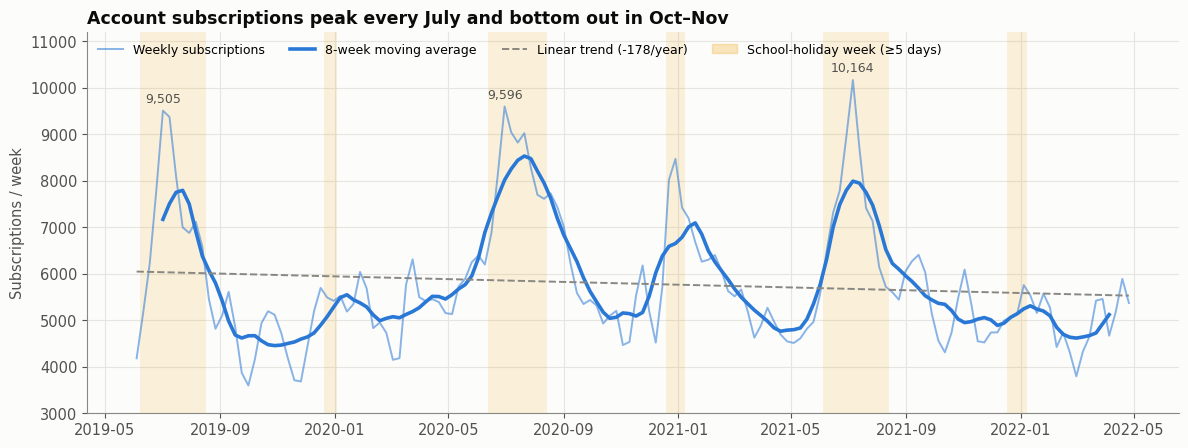

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4.6))
for d in s.loc[s.Holiday >= 5, 'Date']:
    ax.axvspan(d - pd.Timedelta(days=3.5), d + pd.Timedelta(days=3.5), color=C[3], alpha=0.13, lw=0)
ax.plot(s.Date, s.Subs, color=C[0], lw=1.4, alpha=0.55, label='Weekly subscriptions')
ax.plot(s.Date, s.Subs.rolling(8, center=True).mean(), color=C[0], lw=2.6, label='8-week moving average')
t = np.arange(len(s)); b = np.polyfit(t, s.Subs, 1)
ax.plot(s.Date, np.polyval(b, t), color=MUTED, ls='--', lw=1.4, label=f'Linear trend ({b[0]*52:+.0f}/year)')
for d, v in s.nlargest(3, 'Subs')[['Date', 'Subs']].values:
    ax.annotate(f'{v:,.0f}', (d, v), xytext=(0, 6), textcoords='offset points',
                ha='center', fontsize=9, color=INK2)
ax.fill_between([], [], color=C[3], alpha=0.25, label='School-holiday week (≥5 days)')
ax.set_title('Account subscriptions peak every July and bottom out in Oct–Nov')
ax.set_ylabel('Subscriptions / week'); ax.legend(loc='upper left', ncol=4, fontsize=9); ax.set_ylim(3000, 11200)
save(fig, '01_trend')

### 📝 Findings — Trend
- Trung bình **~5,790 đăng ký/tuần** (độ lệch chuẩn ~1,345), dao động từ **3,597** đến **10,164** (gấp ~2.8 lần) → biến động chủ yếu đến từ mùa vụ, không phải xu hướng dài hạn.
- **Xu hướng dài hạn gần như đi ngang**, giảm nhẹ **~178 đăng ký/năm** (~3%/năm).
- Theo năm vận hành (T6 → T5):
  - Y1 **5,496** → Y2 **6,190** (**+12.6%**) → Y3 **5,668** (**−8.4%**).
  - Y2 tăng trùng giai đoạn Meta được đẩy mạnh (2020).
  - Y3 giảm dù có đỉnh cao nhất (10,164 tuần 06/07/2021) → phần còn lại của năm yếu đi; trùng với việc **Meta bị cắt mạnh từ T10/2021** và **click Brand Search giảm** đầu 2022.
- Có **đỉnh phụ quanh Giáng sinh/Năm mới**, mạnh nhất T12/2020 (~8,470) — trùng thời điểm công ty chuyển sang khuyến mãi mức 30 và YouTube tăng vọt.

Month                 1     2      3      4      5     6     7     8     9   \
% so với trung bình 3.00 -9.00 -13.00 -11.00 -10.00 19.00 45.00 11.00 -3.00   

Month                   10     11    12  
% so với trung bình -17.00 -17.00 -4.00  


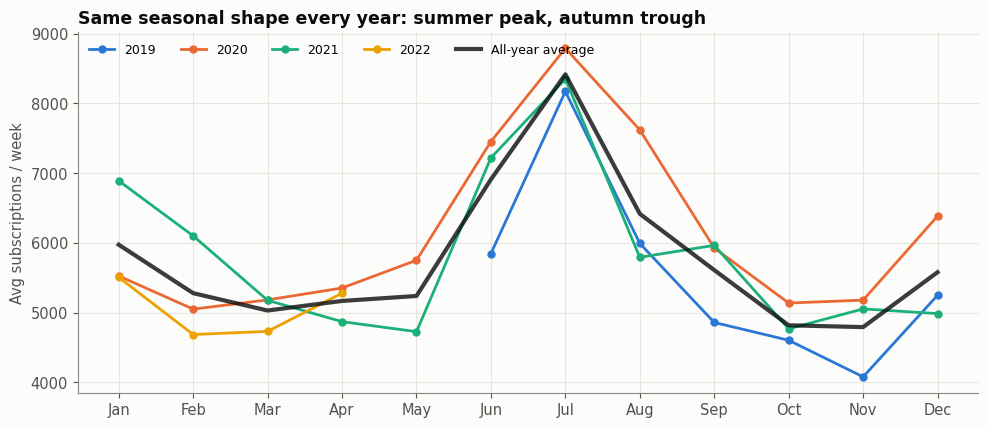

In [ ]:
mo = s.groupby(['Year', 'Month']).Subs.mean().unstack(0)
avg = s.groupby('Month').Subs.mean()
print((avg / s.Subs.mean() * 100 - 100).round(0).rename('% so với trung bình').to_frame().T)

fig, ax = plt.subplots(figsize=(10, 4.4))
for i, y in enumerate(mo.columns):
    ax.plot(mo.index, mo[y], marker='o', ms=5, color=C[i], label=str(y))
ax.plot(avg.index, avg, color=INK, lw=3, alpha=0.8, label='All-year average')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set_title('Same seasonal shape every year: summer peak, autumn trough')
ax.set_ylabel('Avg subscriptions / week'); ax.legend(ncol=5, loc='upper left', fontsize=9)
save(fig, '02_seasonality')

### 📝 Findings — Seasonality
- **Mùa vụ rất rõ và lặp lại cả 3 năm** — các đường theo năm có cùng hình dạng.
- **Đỉnh tháng 7: +45%** so với trung bình; tháng 6 (+19%) và tháng 8 (+11%) cũng cao → mùa hè là mùa cao điểm.
- **Đáy tháng 10–11: −17%**; tháng 2–5 cũng thấp hơn trung bình (−9% đến −13%).
- Đỉnh phụ nhỏ vào tháng 1 (+3%) do nghỉ lễ cuối năm.
- → Mô hình **bắt buộc** phải có biến kiểm soát mùa vụ. Nếu không, các kênh chạy dồn vào mùa hè sẽ "nhận công" của mùa vụ.

School holidays (days)    0.67
Meta                      0.66
Google Brand Search       0.56
YouTube                   0.43
TV                        0.25
Google Generic Search     0.16
Own promotion             0.14
Influencers               0.12
Google Display           -0.01
Competitor promotion     -0.06
dtype: float64


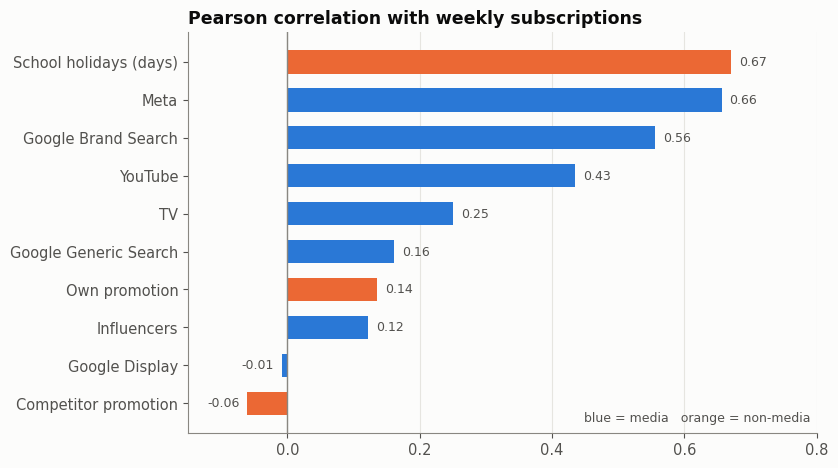

In [ ]:
cols = MEDIA + ['Holiday', 'Promotion', 'Comp_Promo']
r = s[cols].corrwith(s.Subs).sort_values()
print(r.rename(SHORT).sort_values(ascending=False).round(2))

fig, ax = plt.subplots(figsize=(8.5, 4.8))
colors = [C[1] if c in ['Holiday', 'Promotion', 'Comp_Promo'] else C[0] for c in r.index]
ax.barh([SHORT[c] for c in r.index], r.values, color=colors, height=0.62)
for i, v in enumerate(r.values):
    ax.text(v + (0.012 if v >= 0 else -0.012), i, f'{v:.2f}', va='center',
            ha='left' if v >= 0 else 'right', fontsize=9, color=INK2)
ax.axvline(0, color=MUTED, lw=1); ax.set_xlim(-0.15, 0.8); ax.grid(axis='y', visible=False)
ax.set_title('Pearson correlation with weekly subscriptions')
ax.text(0.99, 0.03, 'blue = media   orange = non-media', transform=ax.transAxes,
        ha='right', fontsize=9, color=INK2)
save(fig, '03_correlation')

### 📝 Findings — Correlation (cùng tuần)
- **Kỳ nghỉ học (0.67)** là yếu tố tương quan mạnh nhất, nhỉnh hơn mọi kênh truyền thông.
- Trong các kênh: **Meta (0.66)** > **Google Brand Search (0.56)** > **YouTube (0.43)** > TV (0.25) > Generic Search (0.16) > Influencers (0.12) > Google Display (~0).
- Khuyến mãi của công ty tương quan dương yếu (0.14); khuyến mãi của đối thủ gần như không tương quan (−0.06) khi nhìn thô.
- ⚠️ Tương quan **không phải** nhân quả — hai điểm mù được kiểm tra ở các cell tiếp theo: hiệu ứng trễ và nhiễu mùa vụ.

Độ trễ có tương quan cao nhất:
Google Display           0
Meta                     0
Google Generic Search    0
TV                       4
Influencers              2
Google Brand Search      1
YouTube                  0
dtype: int64


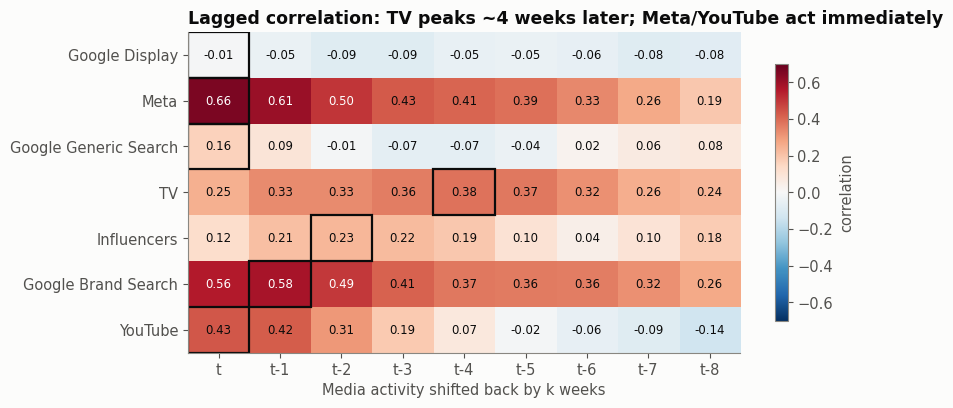

In [ ]:
lags = range(0, 9)
L = pd.DataFrame({l: [s.Subs.corr(s[c].shift(l)) for c in MEDIA] for l in lags},
                 index=[SHORT[c] for c in MEDIA])
print('Độ trễ có tương quan cao nhất:'); print(L.idxmax(axis=1))

fig, ax = plt.subplots(figsize=(9, 4.2))
im = ax.imshow(L.values, cmap='RdBu_r', vmin=-0.7, vmax=0.7, aspect='auto'); ax.grid(False)
ax.set_xticks(range(len(lags))); ax.set_xticklabels([f't-{l}' if l else 't' for l in lags])
ax.set_yticks(range(len(MEDIA))); ax.set_yticklabels(L.index)
for i in range(L.shape[0]):
    for j in range(L.shape[1]):
        v = L.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8.5,
                color='white' if abs(v) > 0.45 else INK)
    jm = int(np.nanargmax(L.values[i]))
    ax.add_patch(plt.Rectangle((jm - .5, i - .5), 1, 1, fill=False, ec=INK, lw=1.6))
ax.set_xlabel('Media activity shifted back by k weeks')
ax.set_title('Lagged correlation: TV peaks ~4 weeks later; Meta/YouTube act immediately')
fig.colorbar(im, ax=ax, shrink=0.8, label='correlation')
save(fig, '04_lag_correlation')

### 📝 Findings — Tương quan trễ (bằng chứng cho Adstock)
- **TV:** tương quan tăng từ 0.25 (cùng tuần) lên **0.38 sau 4 tuần**, và vẫn ~0.3 sau 6 tuần → hiệu ứng **trễ và kéo dài** rõ rệt, đặc trưng của kênh xây dựng thương hiệu. Tương quan cùng tuần **đánh giá thấp** TV.
- **Influencers:** đạt đỉnh sau **2 tuần** (0.23).
- **Google Brand Search:** đạt đỉnh sau **1 tuần** (0.58), rồi giảm dần.
- **Meta, YouTube, Generic Search, Display:** mạnh nhất ngay trong tuần.
  - Meta giảm chậm (0.66 → 0.39 sau 5 tuần) → có hiệu ứng kéo dài.
  - **YouTube tắt hẳn sau ~4–5 tuần** → hiệu ứng ngắn.
- → **Adstock là cần thiết**, nhưng tốc độ "quên" khác nhau giữa các kênh. λ = 0.9 (bán rã ~6.6 tuần) có vẻ hợp với TV, nhưng **quá dài cho YouTube**. Sẽ thử λ riêng từng kênh ở bước tối ưu mô hình.

Tương quan của từng kênh với kỳ nghỉ học:
Meta                     0.48
YouTube                  0.42
Google Brand Search      0.31
TV                       0.15
Influencers              0.13
Google Generic Search   -0.03
Google Display          -0.12
dtype: float64


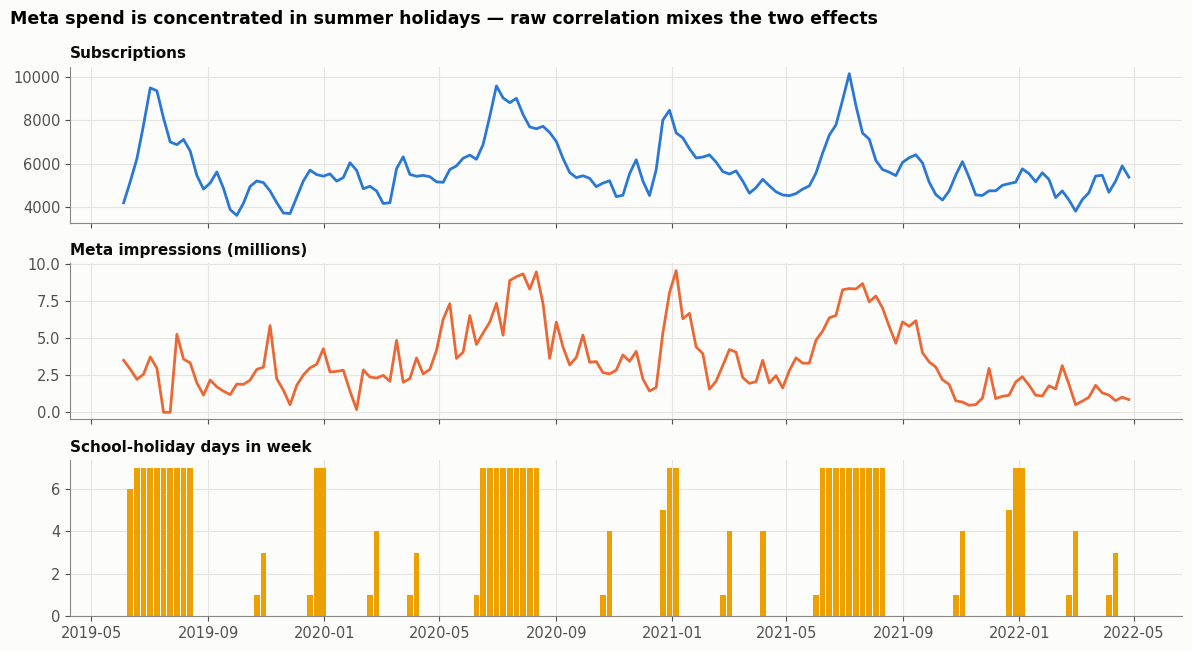

In [ ]:
print('Tương quan của từng kênh với kỳ nghỉ học:')
print(s[MEDIA].corrwith(s.Holiday).rename(SHORT).round(2).sort_values(ascending=False))

fig, axs = plt.subplots(3, 1, figsize=(12, 6.6), sharex=True)
axs[0].plot(s.Date, s.Subs, color=C[0]); axs[0].set_title('Subscriptions', fontsize=11)
axs[1].plot(s.Date, s.Meta_Impressions / 1e6, color=C[1]); axs[1].set_title('Meta impressions (millions)', fontsize=11)
axs[2].bar(s.Date, s.Holiday, width=6, color=C[3]); axs[2].set_title('School-holiday days in week', fontsize=11)
fig.suptitle('Meta spend is concentrated in summer holidays — raw correlation mixes the two effects',
             x=0.01, ha='left', fontweight='bold', fontsize=12.5)
save(fig, '05_confounding_meta_holiday')

### 📝 Findings — Nhiễu (confounding) với kỳ nghỉ học
- **Meta (0.48)** và **YouTube (0.42)** tương quan khá mạnh với kỳ nghỉ học → công ty **dồn ngân sách vào mùa hè**, đúng lúc nhu cầu tự nhiên đã cao.
- Hệ quả: tương quan 0.66 của Meta là **hỗn hợp** của (1) tác động thật của Meta và (2) hiệu ứng mùa hè. Tương quan thô **thổi phồng** hiệu quả của Meta và YouTube.
- TV (0.15), Generic Search (−0.03) và Display (−0.12) ít bị nhiễu bởi kỳ nghỉ.
- → Đây là lý do cần **hồi quy đa biến** có biến kỳ nghỉ: hệ số của Meta khi đó đo tác động **khi giữ kỳ nghỉ cố định**.

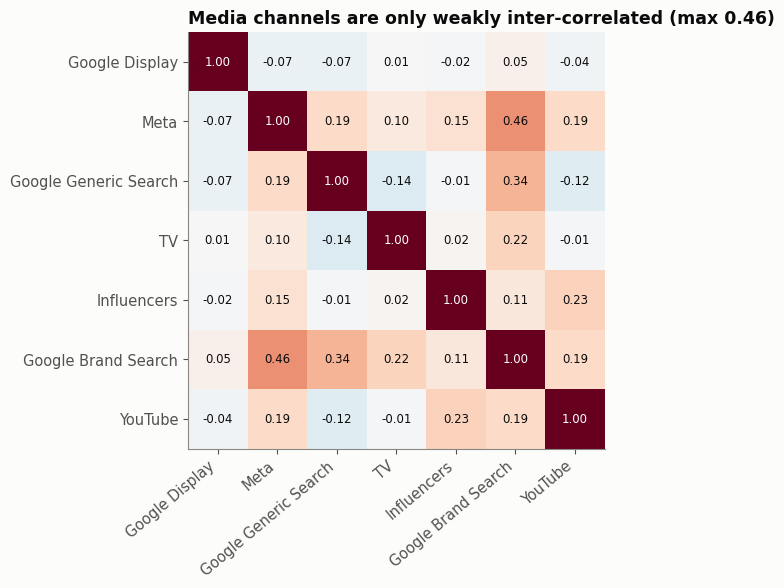

In [ ]:
M = s[MEDIA].corr(); M.index = M.columns = [SHORT[c] for c in MEDIA]
fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(M.values, cmap='RdBu_r', vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(7)); ax.set_xticklabels(M.columns, rotation=40, ha='right')
ax.set_yticks(range(7)); ax.set_yticklabels(M.index)
for i in range(7):
    for j in range(7):
        ax.text(j, i, f'{M.values[i, j]:.2f}', ha='center', va='center', fontsize=8.5,
                color='white' if abs(M.values[i, j]) > .5 else INK)
ax.set_title('Media channels are only weakly inter-correlated (max 0.46)')
save(fig, '09_media_intercorrelation')

### 📝 Findings — Đa cộng tuyến
- Tương quan giữa các kênh đều **thấp**, cao nhất **0.46 (Meta – Brand Search)** → có thể đưa đủ 7 kênh vào mô hình; sẽ kiểm tra VIF khi mô hình hóa.
- Cặp Meta – Brand Search gợi ý **Brand Search một phần là hệ quả** của kênh khác: người xem quảng cáo Meta/TV rồi lên Google tìm tên "Book-Worm". Kết hợp với việc Brand Search phản ứng sau 1 tuần → hệ số và ROI của Brand Search có thể bị **thổi phồng**, còn Meta/TV bị đánh giá thấp.

,mean,count,lift vs 0 days %
HolBucket,,,
0 days,"5,260.48",95,0.00
1–4 days,"5,228.40",20,-0.61
5–7 days,"7,443.99",37,41.51


Tuần nghỉ trọn (≥5 ngày): hè (T6–T8) = 7747 | cuối năm = 6347


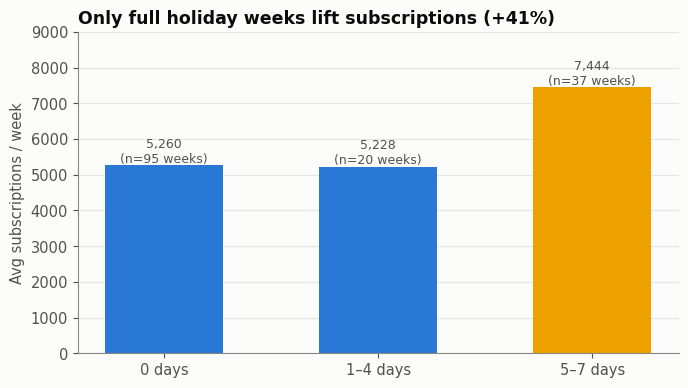

In [ ]:
s['HolBucket'] = pd.cut(s.Holiday, [-1, 0, 4, 7], labels=['0 days', '1–4 days', '5–7 days'])
g = s.groupby('HolBucket', observed=True).Subs.agg(['mean', 'count'])
g['lift vs 0 days %'] = (g['mean'] / g.loc['0 days', 'mean'] - 1) * 100
display(g)

full = s[s.Holiday >= 5]
print('Tuần nghỉ trọn (≥5 ngày): hè (T6–T8) =', round(full[full.Month.isin([6, 7, 8])].Subs.mean()),
      '| cuối năm =', round(full[~full.Month.isin([6, 7, 8])].Subs.mean()))

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(g.index.astype(str), g['mean'], color=[C[0], C[0], C[3]], width=0.55)
for i, (m, n) in enumerate(g[['mean', 'count']].values):
    ax.text(i, m + 80, f'{m:,.0f}\n(n={n:.0f} weeks)', ha='center', fontsize=9, color=INK2)
ax.set_ylim(0, 9000); ax.grid(axis='x', visible=False); ax.set_ylabel('Avg subscriptions / week')
ax.set_title('Only full holiday weeks lift subscriptions (+41%)')
save(fig, '06_school_holidays')

### 📝 Findings — Kỳ nghỉ học
- Tuần **nghỉ trọn (5–7 ngày)**: trung bình **7,444** đăng ký, **+41.5%** so với tuần không nghỉ (5,260).
- Tuần **nghỉ lẻ (1–4 ngày)**: **5,228** — **không khác** tuần đi học (−0.6%).
- → Quan hệ **phi tuyến (dạng bậc thang)**: chỉ kỳ nghỉ dài mới tạo khác biệt. Nếu đưa số ngày nghỉ vào mô hình dạng tuyến tính, mô hình sẽ gán sai tác động cho các tuần nghỉ lẻ.
- **Nghỉ hè mạnh hơn nghỉ cuối năm:** ~**7,750** so với ~**6,350** đăng ký/tuần → mùa hè có thêm yếu tố riêng (thời gian rảnh dài, thói quen đọc sách hè).
- → Ở Bước 2: tạo biến **dummy `Full_Holiday` (Holiday ≥ 5)** thay cho số ngày nghỉ; cân nhắc tách **`Summer_Holiday`** riêng.

Số tuần theo mức khuyến mãi (hàng = công ty, cột = đối thủ):


Comp_Promo,14.00,27.70,30.00
Promotion,,,
14.00,91,0,9
14.30,1,0,0
14.70,1,0,0
15.00,1,0,0
23.10,1,0,1
25.40,1,0,0
27.70,0,0,2
30.00,8,1,35



Khuyến mãi của công ty — chỉ tuần KHÔNG nghỉ học:


,mean,count
Own,,
Own = 14,"5,192.06",65
Own = 30,"5,502.41",23
Transition,"5,100.93",7


Tuần đầu tiên đối thủ ở mức 30: 2021-06-08


mean                           count                
Comp     Competitor = 14 Competitor = 30 Competitor = 14 Competitor = 30
Own                                                                     
Own = 14        5,797.10        4,681.56              91               9
Own = 30        6,727.69        5,994.06               8              35

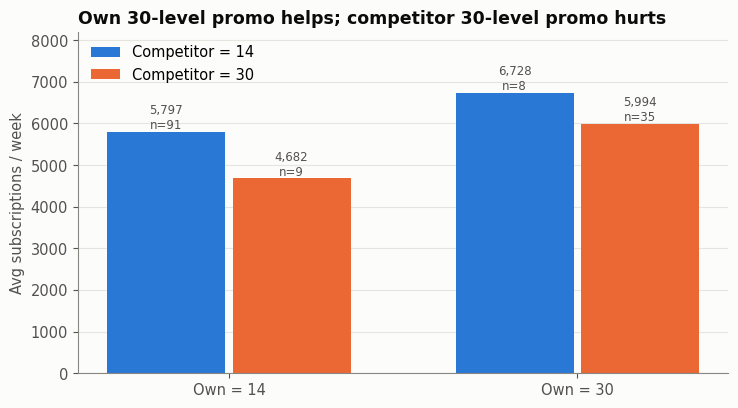

In [ ]:
print('Số tuần theo mức khuyến mãi (hàng = công ty, cột = đối thủ):')
display(pd.crosstab(s.Promotion.round(1), s.Comp_Promo.round(1)))

s['Own'] = np.select([s.Promotion >= 30, s.Promotion <= 14], ['Own = 30', 'Own = 14'], 'Transition')
s['Comp'] = np.select([s.Comp_Promo >= 30, s.Comp_Promo <= 14], ['Competitor = 30', 'Competitor = 14'], 'Transition')

print('\nKhuyến mãi của công ty — chỉ tuần KHÔNG nghỉ học:')
display(s[s.Holiday == 0].groupby('Own').Subs.agg(['mean', 'count']))

# Đối thủ chuyển sang mức 30 từ khi nào?
print('Tuần đầu tiên đối thủ ở mức 30:', s.loc[s.Comp_Promo >= 30, 'Date'].min().date())

pv = s[(s.Own != 'Transition') & (s.Comp != 'Transition')].pivot_table(
    index='Own', columns='Comp', values='Subs', aggfunc=['mean', 'count'])
display(pv)

fig, ax = plt.subplots(figsize=(7.5, 4.2))
x = np.arange(2); w = 0.36
for k, comp in enumerate(['Competitor = 14', 'Competitor = 30']):
    m = pv['mean'][comp].values; n = pv['count'][comp].values
    ax.bar(x + (k - .5) * w, m, w * 0.94, color=C[k], label=comp)
    for xi, mi, ni in zip(x + (k - .5) * w, m, n):
        ax.text(xi, mi + 80, f'{mi:,.0f}\nn={ni:.0f}', ha='center', fontsize=8.5, color=INK2)
ax.set_xticks(x); ax.set_xticklabels(pv.index); ax.set_ylim(0, 8200); ax.grid(axis='x', visible=False)
ax.set_ylabel('Avg subscriptions / week'); ax.legend(loc='upper left')
ax.set_title('Own 30-level promo helps; competitor 30-level promo hurts')
save(fig, '07_promotions')

In [ ]:
# Những tuần nào rơi vào 2 ô nhỏ? → kiểm tra có bị trùng mùa vụ không
for o, c in [('Own = 14', 'Competitor = 30'), ('Own = 30', 'Competitor = 14')]:
    x = s[(s.Own == o) & (s.Comp == c)]
    print(f'{o} & {c}: {len(x)} tuần, {(x.Holiday >= 5).sum()} tuần nghỉ trọn →',
          x.Date.dt.strftime('%m/%Y').unique().tolist())

# Bảng 2×2 chỉ trên tuần KHÔNG nghỉ học
nh = s[(s.Holiday == 0) & (s.Own != 'Transition') & (s.Comp != 'Transition')]
pv_nh = nh.pivot_table(index='Own', columns='Comp', values='Subs', aggfunc=['mean', 'count'])
display(pv_nh)

m = pv_nh['mean']
print(f"Tác động của đối thủ lên mức 30: {m.iloc[0,1]/m.iloc[0,0]-1:+.1%} (khi công ty ở 14), "
      f"{m.iloc[1,1]/m.iloc[1,0]-1:+.1%} (khi công ty ở 30)")
print(f"Tác động của công ty lên mức 30: {m.iloc[1,0]/m.iloc[0,0]-1:+.1%} (khi đối thủ ở 14), "
      f"{m.iloc[1,1]/m.iloc[0,1]-1:+.1%} (khi đối thủ ở 30)")

Own = 14 & Competitor = 30: 9 tuần, 0 tuần nghỉ trọn → ['10/2021', '01/2022', '02/2022', '03/2022']
Own = 30 & Competitor = 14: 8 tuần, 3 tuần nghỉ trọn → ['12/2020', '01/2021', '05/2021']


mean                           count                
Comp     Competitor = 14 Competitor = 30 Competitor = 14 Competitor = 30
Own                                                                     
Own = 14        5,232.04        4,860.79              58               7
Own = 30        5,982.80        5,368.97               5              18

Tác động của đối thủ lên mức 30: -7.1% (khi công ty ở 14), -10.3% (khi công ty ở 30)
Tác động của công ty lên mức 30: +14.3% (khi đối thủ ở 14), +10.5% (khi đối thủ ở 30)


### 📝 Findings — Promotions
- **Bối cảnh:** đối thủ dùng mức 14 suốt đến T5/2021, rồi **chuyển hẳn sang mức 30 từ 08/06/2021** và giữ nguyên đến hết dữ liệu.
- **Bảng 2×2 thô bị nhiễu mùa vụ:** ô "Own 14 + Đối thủ 30" rơi toàn vào mùa thấp điểm (T10/2021, T1–T3/2022), còn ô "Own 30 + Đối thủ 14" rơi vào mùa lễ (T12/2020–T1/2021). So sánh thô (−11% đến −19%) **phóng đại** tác động.
- **Sau khi loại tuần nghỉ học:**
  - Đối thủ lên mức 30 → đăng ký giảm khoảng **−7% đến −10%**.
  - Công ty lên mức 30 → đăng ký tăng khoảng **+10% đến +14%**.
  - Khi đối thủ đã ở mức 30, công ty đáp trả bằng mức 30 giúp **bù lại phần lớn** thiệt hại.
- ⚠️ **Vẫn còn hạn chế:** hiệu ứng đối thủ trùng với giai đoạn Y3 (Meta bị cắt, xu hướng giảm), và một số ô chỉ có 5–7 tuần. Mô hình hồi quy (kiểm soát đồng thời media, kỳ nghỉ, xu hướng) sẽ cho ước lượng đáng tin hơn.
- → Đưa cả `Promotion` và `Comp_Promo` vào mô hình.

Tổng chi phí media: 132,586,224


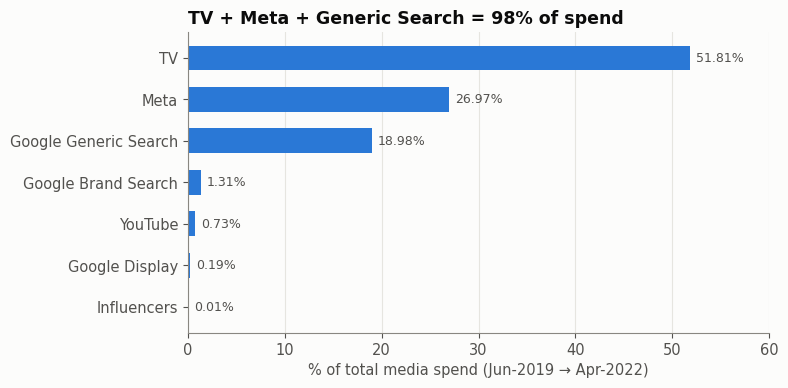

In [ ]:
sp = spend.drop(columns='Date').sum()
share = (sp / sp.sum() * 100)
share.index = [c.replace(' Cost', '').replace('Google Branded Paid Search', 'Google Brand Search')
                .replace('Google Generic Paid Search', 'Google Generic Search') for c in share.index]
share = share.sort_values()
print(f'Tổng chi phí media: {sp.sum():,.0f}')

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(share.index, share.values, color=C[0], height=0.6)
for i, v in enumerate(share.values):
    ax.text(v + 0.6, i, f'{v:.2f}%', va='center', fontsize=9, color=INK2)
ax.set_xlim(0, 60); ax.grid(axis='y', visible=False)
ax.set_xlabel('% of total media spend (Jun-2019 → Apr-2022)')
ax.set_title('TV + Meta + Generic Search = 98% of spend')
save(fig, '08_spend_share')

In [ ]:
def profile(m):
    cost = spend[SPEND_MAP[m]]
    on = sales[m] > 0
    lagc = [sales.Subs.corr(sales[m].shift(l)) for l in range(9)]
    return {'Tổng chi phí': cost.sum(),
            '% ngân sách': cost.sum() / sp.sum() * 100,
            'Số tuần hoạt động': on.sum(),
            'Đăng ký TB tuần có chạy': sales.loc[on, 'Subs'].mean(),
            'Đăng ký TB tuần không chạy': sales.loc[~on, 'Subs'].mean(),
            'Corr cùng tuần': lagc[0],
            'Corr cao nhất': max(lagc),
            'Độ trễ tốt nhất (tuần)': int(np.argmax(lagc)),
            '% tuần chạy rơi vào nghỉ trọn': (sales.loc[on, 'Holiday'] >= 5).mean() * 100}

comp = pd.DataFrame({SHORT[m]: profile(m) for m in
                     ['TV_GRP', 'Influencers_Views', 'Meta_Impressions', 'YouTube_Impressions']})
comp

,TV,Influencers,Meta,YouTube
Tổng chi phí,"68,688,903.23","17,142.00","35,761,611.03","972,324.18"
% ngân sách,51.81,0.01,26.97,0.73
Số tuần hoạt động,41.00,38.00,150.00,152.00
Đăng ký TB tuần có chạy,"6,414.76","6,139.63","5,764.31","5,787.77"
Đăng ký TB tuần không chạy,"5,556.18","5,670.49","7,547.75",NaN
Corr cùng tuần,0.25,0.12,0.66,0.43
Corr cao nhất,0.38,0.23,0.66,0.43
Độ trễ tốt nhất (tuần),4.00,2.00,0.00,0.00
% tuần chạy rơi vào nghỉ trọn,41.46,36.84,23.33,24.34


### 📝 Findings — Influencer vs TV
- **Quy mô đầu tư chênh lệch cực lớn:** TV chiếm **51.8%** tổng ngân sách (~68.7 triệu), Influencers chỉ **0.01%** (~17 nghìn) — chênh ~4,000 lần. TV + Meta + Generic Search chiếm **98%** ngân sách.
- **Tần suất:** cả hai đều chạy theo đợt — TV 41 tuần, Influencers 38 tuần (so với Meta 150 tuần, YouTube 152 tuần chạy liên tục).
- **Tốc độ tác động:**
  - **TV** tác động **trễ và kéo dài** (đỉnh sau 4 tuần, corr 0.25 → 0.38) → kênh xây dựng nhận biết thương hiệu.
  - **Influencers** tác động trễ ngắn hơn (đỉnh sau 2 tuần, corr 0.12 → 0.23), tín hiệu yếu.
- **Chênh lệch "có chạy / không chạy" bị nhiễu mùa vụ:** 41% số tuần chạy TV và 37% số tuần chạy Influencers rơi vào kỳ nghỉ trọn, so với mốc 24% của toàn bộ dữ liệu → mức chênh +15% (TV) và +8% (Influencers) **phần lớn do mùa hè**, không phải do kênh.
- **Kết luận ở giai đoạn EDA:** chưa thể nói kênh nào hiệu quả hơn. Câu trả lời sẽ đến từ **ROI theo mô hình** ở Bước 4. Giả thuyết cần kiểm chứng: Influencers có thể có **ROI cao** (chi rất ít) nhưng **đóng góp tuyệt đối nhỏ**; TV ngược lại — đóng góp lớn nhưng ROI thấp do chi phí khổng lồ.

### 📋 Tổng kết EDA & hàm ý cho Feature Engineering / Modeling

| # | Phát hiện | Hàm ý |
|---|---|---|
| 1 | Mùa vụ mạnh: đỉnh T7 (+45%), đáy T10–11 (−17%), lặp lại cả 3 năm | Bắt buộc có biến kiểm soát mùa vụ |
| 2 | Chỉ tuần nghỉ trọn (≥5 ngày) mới tăng đăng ký (+41%); hè mạnh hơn cuối năm | Dummy `Full_Holiday`; cân nhắc tách `Summer_Holiday` |
| 3 | Meta/YouTube chạy dồn vào mùa hè (corr 0.48/0.42 với kỳ nghỉ) | Tương quan thô thổi phồng hiệu quả → cần hồi quy đa biến |
| 4 | TV đạt đỉnh tác động sau ~4 tuần; YouTube tắt sau ~4–5 tuần | Adstock cần thiết; λ nên khác nhau theo kênh |
| 5 | Brand Search phản ứng sau 1 tuần, tương quan 0.46 với Meta | Có thể là hệ quả của kênh khác → ROI dễ bị thổi phồng |
| 6 | Đối thủ ở mức 30: −7% đến −10%; công ty ở mức 30: +10% đến +14% (tuần không nghỉ) | Đưa cả `Promotion` và `Comp_Promo` vào mô hình |
| 7 | Đa cộng tuyến thấp (max 0.46) | Có thể đưa đủ 7 kênh; kiểm tra VIF |
| 8 | Chi phí TV ghi sổ lệch thời gian so với GRP; dữ liệu Influencer lặp lại | Ghi chú hạn chế dữ liệu trong báo cáo |
| 9 | Xu hướng dài hạn giảm nhẹ (−178/năm) | Cân nhắc thêm biến `Trend` |

## 3. Feature engineering

In [ ]:
def adstock(x, lam=0.9):
    """A_t = X_t + lam * A_{t-1}, bắt đầu với A_{-1} = 0."""
    x = np.asarray(x, dtype=float)
    a = np.zeros_like(x)
    for t in range(len(x)):
        a[t] = x[t] + (lam * a[t - 1] if t > 0 else 0)
    return a

def sma(x, window=10):
    """Trung bình 10 tuần GẦN NHẤT (chỉ nhìn quá khứ → không rò rỉ tương lai)."""
    return pd.Series(x).rolling(window, min_periods=1).mean().values

def build_features(df, lam=0.9, window=10):
    """Dùng chung cho dữ liệu lịch sử VÀ dữ liệu kịch bản ở Bước 5."""
    f = df.copy()
    # --- Composite features ---
    f['Google_Impressions']  = f.Google_Display_Impressions + f.Google_Generic_Paid_Search_Impressions
    f['Digital_Impressions'] = f.Google_Impressions + f.Meta_Impressions + f.YouTube_Impressions
    # --- SMA & Adstock cho từng kênh (kể cả composite) ---
    for c in MEDIA + ['Google_Impressions', 'Digital_Impressions']:
        f[f'{c}_SMA10']   = sma(f[c], window)
        f[f'{c}_Adstock'] = adstock(f[c], lam)
    # --- Biến kiểm soát ---
    f['Full_Holiday']   = (f.Holiday >= 5).astype(int)
    f['Summer_Holiday'] = ((f.Holiday >= 5) & f.Date.dt.month.isin([6, 7, 8])).astype(int)
    f['Trend']          = np.arange(len(f))
    return f

feat = build_features(sales)
print(feat.shape)
feat.filter(like='TV_GRP').head(8)

(152, 35)


,TV_GRP,TV_GRP_SMA10,TV_GRP_Adstock
0,0.00,0.00,0.00
1,0.00,0.00,0.00
2,274.29,91.43,274.29
3,"1,920.00",548.57,"2,166.86"
4,"1,920.00",822.86,"3,870.17"
5,"1,920.00","1,005.71","5,403.15"
6,"1,645.71","1,097.14","6,508.55"
7,0.00,960.00,"5,857.70"


In [ ]:
comp_cols = ['Google_Display_Impressions', 'Google_Generic_Paid_Search_Impressions', 'Google_Impressions',
             'Meta_Impressions', 'YouTube_Impressions', 'Digital_Impressions']
print('Tương quan với số đăng ký:')
print(feat[comp_cols].corrwith(feat.Subs).round(3))

# Composite bị kênh nào chi phối?
shares = feat[['Google_Display_Impressions', 'Google_Generic_Paid_Search_Impressions',
               'Meta_Impressions', 'YouTube_Impressions']].sum()
print('\nTỷ trọng trong Digital_Impressions (%):')
print((shares / shares.sum() * 100).round(1))

Tương quan với số đăng ký:
Google_Display_Impressions               -0.01
Google_Generic_Paid_Search_Impressions    0.16
Google_Impressions                        0.14
Meta_Impressions                          0.66
YouTube_Impressions                       0.43
Digital_Impressions                       0.66
dtype: float64

Tỷ trọng trong Digital_Impressions (%):
Google_Display_Impressions                0.50
Google_Generic_Paid_Search_Impressions    9.70
Meta_Impressions                         89.60
YouTube_Impressions                       0.20
dtype: float64


### 📝 Findings — Composite features
- **`Digital_Impressions` gần như chính là Meta:** Meta chiếm **89.6%** tổng impressions digital (Generic 9.7%, Display 0.5%, YouTube 0.2%) → tương quan của composite (0.66) **bằng đúng** của Meta. Gộp lại **không thêm thông tin mới**, chỉ "pha loãng" các kênh nhỏ vào Meta.
- **`Google_Impressions`** (Display + Generic) tương quan 0.14 — do Generic chi phối (Display chỉ chiếm ~5% impressions Google).
- **Vấn đề của phép cộng:** nó giả định 1 impression YouTube = 1 impression Meta = 1 impression Display. YouTube chỉ chiếm 0.2% impressions nhưng tương quan riêng 0.43 → giá trị mỗi impression của YouTube cao hơn nhiều, và bị "chìm" khi cộng.
- **Kết luận:** composite hữu ích để kể câu chuyện "tổng digital", nhưng **không dùng được để tính ROI từng kênh**. Ta vẫn giữ biến riêng từng kênh cho mô hình chính; composite sẽ được thử như một mô hình đối chứng.

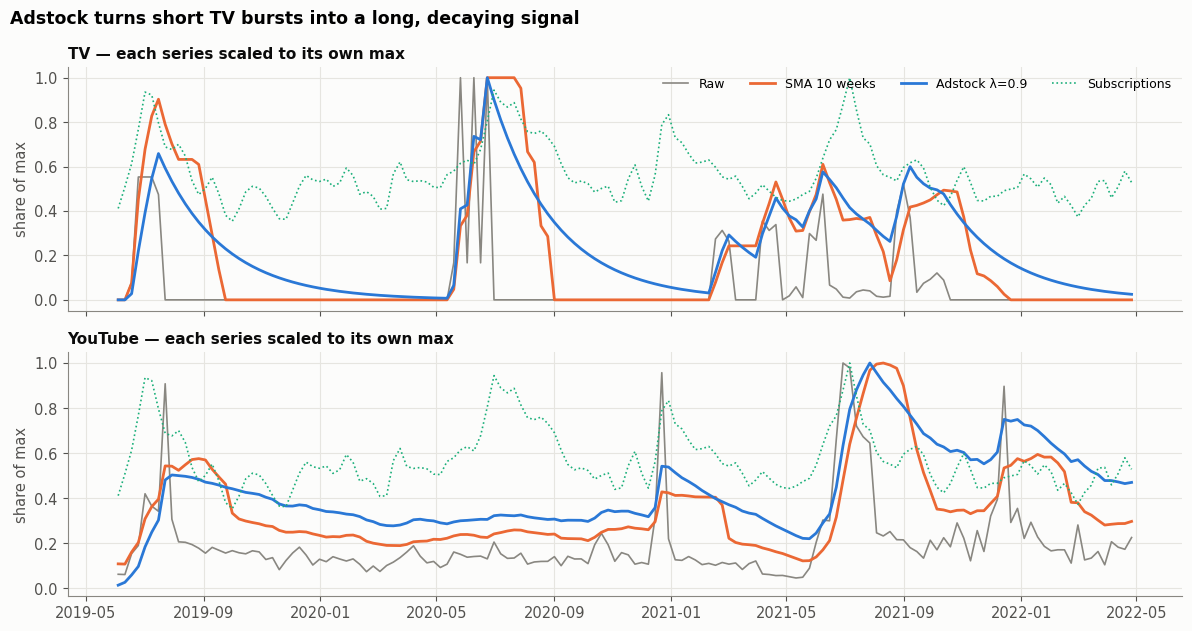

In [ ]:
fig, axs = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True)
for ax, m in zip(axs, ['TV_GRP', 'YouTube_Impressions']):
    for col, lab, colr, lw in [(m, 'Raw', MUTED, 1.2),
                               (f'{m}_SMA10', 'SMA 10 weeks', C[1], 2),
                               (f'{m}_Adstock', 'Adstock λ=0.9', C[0], 2)]:
        ax.plot(feat.Date, feat[col] / feat[col].max(), color=colr, lw=lw, label=lab)
    ax2_subs = feat.Subs / feat.Subs.max()
    ax.plot(feat.Date, ax2_subs, color=C[2], lw=1.2, ls=':', label='Subscriptions')
    ax.set_title(f'{SHORT[m]} — each series scaled to its own max', fontsize=11)
    ax.set_ylabel('share of max')
axs[0].legend(ncol=4, loc='upper right', fontsize=9)
fig.suptitle('Adstock turns short TV bursts into a long, decaying signal',
             x=0.01, ha='left', fontweight='bold', fontsize=12.5)
save(fig, '10_raw_sma_adstock')

,Raw,SMA10,Adstock,Tốt nhất
Google Display,-0.01,-0.13,-0.08,Raw
Meta,0.66,0.47,0.36,Raw
Google Generic Search,0.16,0.01,0.02,Raw
TV,0.25,0.60,0.54,SMA10
Influencers,0.12,0.35,0.31,SMA10
Google Brand Search,0.56,0.50,0.27,Raw
YouTube,0.43,0.16,0.04,Raw
Digital (composite),0.66,0.47,0.34,Raw


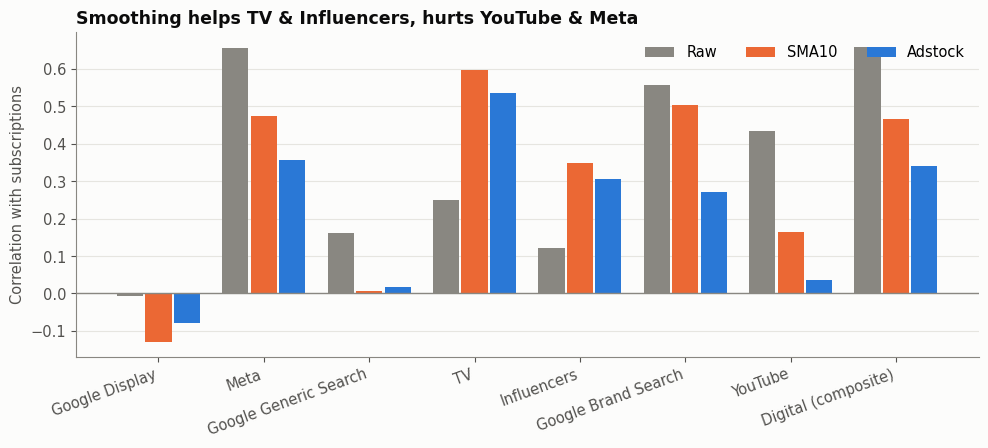

In [ ]:
rows = {}
for m in MEDIA + ['Digital_Impressions']:
    rows[SHORT.get(m, 'Digital (composite)')] = {
        'Raw':     feat.Subs.corr(feat[m]),
        'SMA10':   feat.Subs.corr(feat[f'{m}_SMA10']),
        'Adstock': feat.Subs.corr(feat[f'{m}_Adstock'])}
tr = pd.DataFrame(rows).T
tr['Tốt nhất'] = tr.idxmax(axis=1)
display(tr.round(3))

fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(tr)); w = 0.27
for k, (col, colr) in enumerate([('Raw', MUTED), ('SMA10', C[1]), ('Adstock', C[0])]):
    ax.bar(x + (k - 1) * w, tr[col], w * 0.92, color=colr, label=col)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(x); ax.set_xticklabels(tr.index, rotation=20, ha='right'); ax.grid(axis='x', visible=False)
ax.set_ylabel('Correlation with subscriptions'); ax.legend(ncol=3, loc='upper right')
ax.set_title('Smoothing helps TV & Influencers, hurts YouTube & Meta')
save(fig, '11_transform_correlation')

### 📝 Findings — Raw vs SMA10 vs Adstock λ=0.9
Các kênh chia thành **hai nhóm rõ rệt**:

| Nhóm | Kênh | Raw → SMA10 / Adstock | Diễn giải |
|---|---|---|---|
| **Trí nhớ dài** | TV | 0.25 → **0.60** / **0.54** | Làm mượt giúp **tăng gấp đôi** tương quan |
| | Influencers | 0.12 → **0.35** / **0.31** | Tăng gần gấp 3 |
| **Phản ứng nhanh** | YouTube | **0.43** → 0.16 / 0.04 | Adstock λ=0.9 **xóa sạch** tín hiệu |
| | Meta | **0.66** → 0.47 / 0.36 | Giảm mạnh |
| | Brand Search | **0.56** → 0.50 / 0.27 | Giảm một nửa với adstock |
| | Generic Search | **0.16** → 0.01 / 0.02 | Mất tín hiệu |

- **Khớp hoàn toàn với tương quan trễ ở EDA:** TV đạt đỉnh sau 4 tuần → hưởng lợi từ trí nhớ dài; YouTube tắt sau ~4 tuần → bị "làm nhòe" khi giả định trí nhớ ~6.6 tuần.
- **Vì sao Adstock λ=0.9 làm hỏng kênh nhanh:** với λ=0.9, giá trị adstock tuần này chỉ ~10% đến từ quảng cáo tuần này, ~90% là quá khứ tích lũy. Một đợt YouTube tăng vọt bị trải mỏng ra 10–20 tuần, trong khi số đăng ký phản ứng ngay → hai chuỗi lệch pha.
- → **Hệ quả cho Bước 3:** dùng **một λ chung = 0.9 cho mọi kênh** gần như chắc chắn cho mô hình kém hơn. Cần **tối ưu λ riêng cho từng kênh**: λ cao cho TV/Influencers, λ thấp cho YouTube/Meta/Search.
- Lưu ý: đây vẫn là tương quan đơn biến (chưa kiểm soát mùa vụ) → chỉ là gợi ý, mô hình sẽ kiểm chứng.

In [ ]:
print(feat[['Holiday', 'Full_Holiday', 'Summer_Holiday']].corrwith(feat.Subs).round(3))

Holiday          0.67
Full_Holiday     0.70
Summer_Holiday   0.71
dtype: float64


### 📝 Findings — Biến kiểm soát kỳ nghỉ
- `Full_Holiday` (0.70) và `Summer_Holiday` (0.71) đều tương quan **cao hơn** số ngày nghỉ gốc (0.67) → **xác nhận quan hệ bậc thang** từ EDA: điều quan trọng là "có phải tuần nghỉ trọn không", không phải "nghỉ bao nhiêu ngày".
- Hai biến sẽ cùng vào mô hình: `Full_Holiday` đo hiệu ứng **mọi** kỳ nghỉ trọn, `Summer_Holiday` đo **phần cộng thêm** riêng của mùa hè.

## 4. Train/test split & baseline models

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error

N_TRAIN = 122
train, test = feat.iloc[:N_TRAIN], feat.iloc[N_TRAIN:]
print(f'Train: {train.Date.min().date()} → {train.Date.max().date()}  ({len(train)} tuần)')
print(f'Test : {test.Date.min().date()} → {test.Date.max().date()}  ({len(test)} tuần)')
print(f'Độ lệch chuẩn số đăng ký — train: {train.Subs.std():,.0f} | test: {test.Subs.std():,.0f}')

# Baseline: mô hình phải tốt hơn cách đoán ngây thơ
naive_mean = mean_absolute_percentage_error(test.Subs, np.full(len(test), train.Subs.mean())) * 100
naive_ly   = mean_absolute_percentage_error(test.Subs, feat.Subs.shift(52).iloc[N_TRAIN:]) * 100
print(f'Baseline MAPE — trung bình train: {naive_mean:.1f}% | cùng tuần năm trước: {naive_ly:.1f}%')

CONTROLS = ['Full_Holiday', 'Summer_Holiday', 'Promotion', 'Comp_Promo']

def fit_eval(media_cols, name, controls=CONTROLS, verbose=False):
    """Fit OLS trên train, đánh giá trên test, trả về (model, bảng chỉ số)."""
    cols = media_cols + controls
    X_tr = sm.add_constant(train[cols], has_constant='add')
    X_te = sm.add_constant(test[cols],  has_constant='add')
    model = sm.OLS(train.Subs, X_tr).fit()
    pred_tr, pred_te = model.predict(X_tr), model.predict(X_te)
    vif = max(variance_inflation_factor(X_tr.values, i) for i in range(1, X_tr.shape[1]))
    m = {'Model': name,
         'Adj R² (train)': model.rsquared_adj,
         'AIC': model.aic,
         'MAPE train %': mean_absolute_percentage_error(train.Subs, pred_tr) * 100,
         'MAPE test %':  mean_absolute_percentage_error(test.Subs, pred_te) * 100,
         'RMSE test': mean_squared_error(test.Subs, pred_te) ** 0.5,
         'Bias test': (test.Subs - pred_te).mean(),          # >0: mô hình dự đoán THẤP hơn thực tế
         '# hệ số media < 0': int((model.params[media_cols] < 0).sum()),
         '# media p>0.05':   int((model.pvalues[media_cols] > 0.05).sum()),
         'VIF max': vif}
    if verbose:
        print(model.summary(slim=True))
    return model, m

Train: 2019-06-04 → 2021-09-28  (122 tuần)
Test : 2021-10-05 → 2022-04-26  (30 tuần)
Độ lệch chuẩn số đăng ký — train: 1,411 | test: 542
Baseline MAPE — trung bình train: 21.4% | cùng tuần năm trước: 22.8%


### 📝 Findings — Chia dữ liệu & baseline
- **Train:** 122 tuần (04/06/2019 → 28/09/2021, có 3 mùa hè). **Test:** 30 tuần (05/10/2021 → 26/04/2022, **không có mùa hè**).
- Độ lệch chuẩn test (**542**) chỉ bằng ~1/3 train (**1,411**) → R² trên test dễ âm dù mô hình tốt → dùng **MAPE** làm thước đo chính trên test.
- **Baseline MAPE:** đoán bằng trung bình train **21.4%**, đoán bằng cùng tuần năm trước **22.8%** → mô hình nào có MAPE test dưới ~21% mới thực sự học được điều gì đó.

In [ ]:
m1, r1 = fit_eval(MEDIA, 'M1: Raw', verbose=True)

                            OLS Regression Results                            
Dep. Variable:                   Subs   R-squared:                       0.796
Model:                            OLS   Adj. R-squared:                  0.776
No. Observations:                 122   F-statistic:                     39.04
Covariance Type:            nonrobust   Prob (F-statistic):           6.21e-33
                                             coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------
const                                   3539.5434    307.943     11.494      0.000    2929.273    4149.814
Google_Display_Impressions                 0.0015      0.001      1.713      0.089      -0.000       0.003
Meta_Impressions                           0.0001   4.35e-05      3.280      0.001    5.65e-05       0.000
Google_Generic_Paid_Search_Impressions     0.0024      0.001      3.47

In [ ]:
m2a, r2a = fit_eval([f'{c}_Adstock' for c in MEDIA], 'M2a: Adstock λ=0.9', verbose=True)
m2b, r2b = fit_eval([f'{c}_SMA10' for c in MEDIA], 'M2b: SMA 10')
m2c, r2c = fit_eval(['Digital_Impressions_Adstock', 'TV_GRP_Adstock', 'Influencers_Views_Adstock',
                     'Google_Brand_Paid_Search_Clicks_Adstock'], 'M2c: Composite Digital + Adstock')

results = pd.DataFrame([r1, r2a, r2b, r2c]).set_index('Model')
results.round(2)

                            OLS Regression Results                            
Dep. Variable:                   Subs   R-squared:                       0.719
Model:                            OLS   Adj. R-squared:                  0.691
No. Observations:                 122   F-statistic:                     25.63
Covariance Type:            nonrobust   Prob (F-statistic):           1.68e-25
                                                     coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------
const                                           3845.7709    377.826     10.179      0.000    3097.009    4594.533
Google_Display_Impressions_Adstock                -0.0006      0.000     -1.498      0.137      -0.001       0.000
Meta_Impressions_Adstock                         5.54e-06   1.13e-05      0.488      0.626   -1.69e-05     2.8e-05
Google_Generic_Paid_Search_Imp

,Adj R² (train),AIC,MAPE train %,MAPE test %,RMSE test,Bias test,# hệ số media < 0,# media p>0.05,VIF max
Model,,,,,,,,,
M1: Raw,0.78,"1,944.77",8.72,10.88,718.01,300.42,1,2,7.07
M2a: Adstock λ=0.9,0.69,"1,983.72",10.15,13.45,803.98,133.16,3,5,15.68
M2b: SMA 10,0.70,"1,981.63",9.82,12.18,716.99,34.29,2,5,8.77
M2c: Composite Digital + Adstock,0.69,"1,980.70",10.35,11.79,710.17,66.64,0,2,7.62


,M1 β,M1 p,M2a β,M2a p
Google Display,1.47e-03,8.94e-02,-6.20e-04,1.37e-01
Meta,1.43e-04,1.39e-03,5.54e-06,6.26e-01
Google Generic Search,2.37e-03,7.26e-04,-1.76e-04,4.41e-01
TV,3.19e-01,1.04e-03,7.50e-02,1.07e-01
Influencers,-7.44e-01,1.48e-01,6.80e-01,3.09e-02
Google Brand Search,1.21e-01,3.20e-02,4.88e-02,2.82e-02
YouTube,7.95e-02,6.18e-07,-3.64e-03,4.86e-01


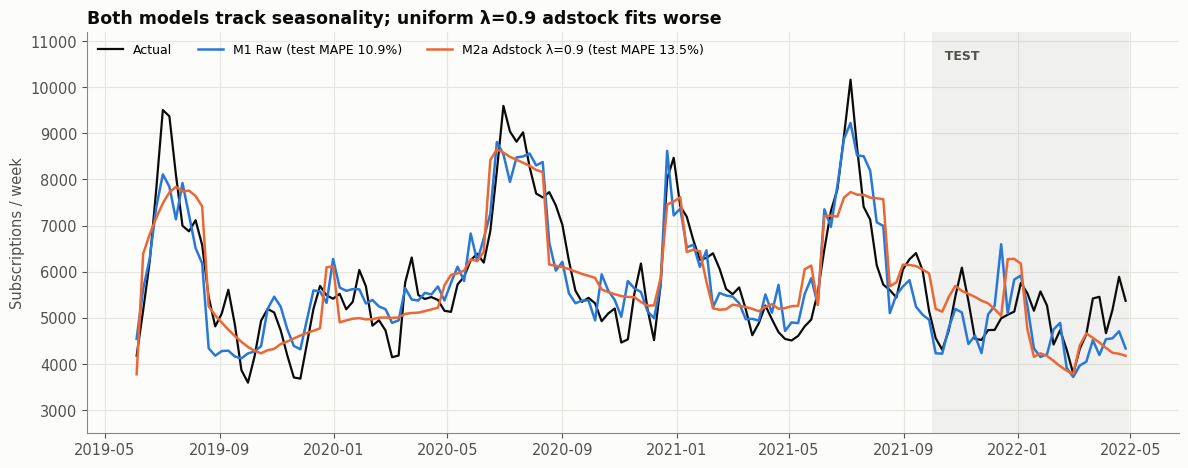

In [ ]:
coef = pd.DataFrame({
    'M1 β':  m1.params[MEDIA].values,
    'M1 p':  m1.pvalues[MEDIA].values,
    'M2a β': m2a.params[[f'{c}_Adstock' for c in MEDIA]].values,
    'M2a p': m2a.pvalues[[f'{c}_Adstock' for c in MEDIA]].values,
}, index=[SHORT[c] for c in MEDIA])
display(coef.style.format('{:.2e}'))   # hiển thị dạng khoa học, ví dụ 1.43e-04

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.axvspan(test.Date.min() - pd.Timedelta(days=3.5), test.Date.max() + pd.Timedelta(days=3.5),
           color=MUTED, alpha=0.10, lw=0)
ax.text(test.Date.min(), 10600, '  TEST', color=INK2, fontsize=9, fontweight='bold')
ax.plot(feat.Date, feat.Subs, color=INK, lw=1.6, label='Actual')
for model, cols, name, colr in [
        (m1,  MEDIA, f"M1 Raw (test MAPE {r1['MAPE test %']:.1f}%)", C[0]),
        (m2a, [f'{c}_Adstock' for c in MEDIA], f"M2a Adstock λ=0.9 (test MAPE {r2a['MAPE test %']:.1f}%)", C[1])]:
    X_all = sm.add_constant(feat[cols + CONTROLS], has_constant='add')
    ax.plot(feat.Date, model.predict(X_all), color=colr, lw=1.8, label=name)
ax.set_ylim(2500, 11200); ax.set_ylabel('Subscriptions / week')
ax.legend(loc='upper left', ncol=3, fontsize=9)
ax.set_title('Both models track seasonality; uniform λ=0.9 adstock fits worse')
save(fig, '12_actual_vs_pred_m1_m2')

### 📝 Findings — Model 1 vs Model 2

**Model 1 (biến gốc)** khá tốt: Adj R² **0.78**, MAPE test **10.9%** (bằng một nửa baseline). Nhưng có 2 vấn đề:
- **Influencers có β âm (−0.74)** → "chạy influencer làm giảm đăng ký" — vô lý về kinh doanh (dù p = 0.15, không có ý nghĩa thống kê).
- Giả định quảng cáo chỉ tác động **trong đúng tuần chạy** → mâu thuẫn với EDA (TV đạt đỉnh sau 4 tuần).

**Model 2a (Adstock λ = 0.9 cho mọi kênh, đúng đề bài) kém hơn M1 ở mọi tiêu chí:**
- Adj R² giảm 0.78 → **0.69**, AIC tăng 1,945 → **1,984**, MAPE test 10.9% → **13.5%**.
- **3 kênh có β âm** (Display, Generic Search, YouTube), **5/7 kênh mất ý nghĩa thống kê** (Meta p = 0.63, YouTube p = 0.49).
- **VIF tăng lên 15.7** (> 10): với λ = 0.9, các chuỗi adstock đều trở nên mượt và chậm → chúng **giống nhau hơn** → mô hình khó tách công từng kênh.
- **Nguyên nhân:** đúng như Bước 2 dự báo — λ = 0.9 (bán rã 6.6 tuần) làm nhòe tín hiệu của các kênh phản ứng nhanh (Meta, YouTube, Search). Chỉ TV, Influencers, Brand Search giữ được hệ số dương.

**M2b (SMA 10)** và **M2c (Composite)** cũng không vượt M1. M2c không có hệ số âm, nhưng gộp Meta–Google–YouTube làm mất khả năng tính ROI từng kênh.

→ **Kết luận:** ý tưởng adstock đúng (EDA có bằng chứng hiệu ứng trễ), nhưng **một λ chung cho mọi kênh là sai**. Bước tối ưu sẽ tìm λ riêng cho từng kênh.

## 5. Per-channel adstock (λ) optimisation

In [ ]:
LAMBDA_GRID = np.round(np.arange(0, 1.0, 0.1), 1)       # 0.0, 0.1, ..., 0.9

def media_matrix(df, lams, sats=None):
    """Biến đổi 7 kênh theo λ (và căn bậc hai nếu sats[m] = True)."""
    X = pd.DataFrame(index=df.index)
    for m in MEDIA:
        a = adstock(df[m], lams[m])
        X[m] = np.sqrt(a) if (sats and sats[m]) else a
    return X

def train_aic(lams, sats=None):
    X = sm.add_constant(pd.concat([media_matrix(feat, lams, sats), feat[CONTROLS]], axis=1),
                        has_constant='add')
    return sm.OLS(train.Subs, X.iloc[:N_TRAIN]).fit().aic

def search_lambda(allow_sat=False, n_rounds=4):
    """Coordinate descent theo AIC trên TRAIN. Không dùng test."""
    lams = {m: 0.0 for m in MEDIA}
    sats = {m: False for m in MEDIA}
    best = train_aic(lams, sats)
    for r in range(n_rounds):
        changed = False
        for m in MEDIA:
            for lam in LAMBDA_GRID:
                for sat in ([False, True] if allow_sat else [False]):
                    L, S = {**lams, m: lam}, {**sats, m: sat}
                    aic = train_aic(L, S)
                    if aic < best - 1e-9:
                        best, lams, sats, changed = aic, L, S, True
        print(f'  vòng {r+1}: AIC = {best:.1f}')
        if not changed:
            break
    return lams, sats

print('M3 — tối ưu λ từng kênh:')
LAM_OPT, _ = search_lambda(allow_sat=False)
print('M4 — tối ưu λ + saturation (căn bậc hai):')
LAM_SAT, SAT_SAT = search_lambda(allow_sat=True)

# So λ tìm được với bằng chứng từ EDA
half_life = lambda l: np.log(0.5) / np.log(l) if l > 0 else 0
best_lag = {m: int(np.argmax([feat.Subs.corr(feat[m].shift(k)) for k in range(9)])) for m in MEDIA}
lam_tbl = pd.DataFrame({
    'λ (M3)': [LAM_OPT[m] for m in MEDIA],
    'Bán rã (tuần)': [half_life(LAM_OPT[m]) for m in MEDIA],
    'Trễ tốt nhất ở EDA': [best_lag[m] for m in MEDIA],
    'λ (M4)': [LAM_SAT[m] for m in MEDIA],
    'Saturation (M4)': ['√' if SAT_SAT[m] else '' for m in MEDIA],
}, index=[SHORT[m] for m in MEDIA])
display(lam_tbl.round(1))

M3 — tối ưu λ từng kênh:
  vòng 1: AIC = 1920.3
  vòng 2: AIC = 1920.0
  vòng 3: AIC = 1920.0
M4 — tối ưu λ + saturation (căn bậc hai):
  vòng 1: AIC = 1908.7
  vòng 2: AIC = 1907.6
  vòng 3: AIC = 1907.4
  vòng 4: AIC = 1907.4


,λ (M3),Bán rã (tuần),Trễ tốt nhất ở EDA,λ (M4),Saturation (M4)
Google Display,0.30,0.60,0,0.00,√
Meta,0.50,1.00,0,0.40,√
Google Generic Search,0.00,0.00,0,0.10,
TV,0.80,3.10,4,0.80,√
Influencers,0.90,6.60,2,0.90,
Google Brand Search,0.20,0.40,1,0.20,
YouTube,0.20,0.40,0,0.20,√


### 📝 Findings — λ tối ưu từng kênh
- Coordinate descent hội tụ sau **3 vòng** (AIC 1920.0). λ được chọn **chỉ dựa trên AIC của train** — không nhìn tập test.
- **λ tìm được khớp với bằng chứng EDA** (dù thuật toán không hề "biết" kết quả EDA):

| Kênh | λ | Bán rã | Trễ tốt nhất ở EDA | Diễn giải |
|---|---|---|---|---|
| TV | **0.8** | 3.1 tuần | 4 tuần | Trí nhớ dài — kênh thương hiệu |
| Influencers | **0.9** | 6.6 tuần | 2 tuần | Trí nhớ dài (nhưng tín hiệu yếu) |
| Meta | 0.5 | 1.0 tuần | 0 | Kéo dài vừa phải |
| Display | 0.3 | 0.6 tuần | 0 | Ngắn |
| Brand Search, YouTube | 0.2 | 0.4 tuần | 0–1 | Gần như tức thời |
| Generic Search | **0.0** | 0 | 0 | Không carry-over — đúng bản chất search: tìm → click → đăng ký ngay |

- **Chỉ có Influencers** thực sự cần λ = 0.9 như đề bài → giải thích vì sao M2a thất bại.
- **M4 (thêm saturation)** chọn căn bậc hai cho Display, Meta, TV, YouTube → gợi ý các kênh này có **hiệu suất giảm dần**: chạy càng nhiều, mỗi đơn vị thêm càng ít hiệu quả.

In [ ]:
for m in MEDIA:
    feat[f'{m}_AdOpt'] = adstock(feat[m], LAM_OPT[m])
    a = adstock(feat[m], LAM_SAT[m])
    feat[f'{m}_AdSat'] = np.sqrt(a) if SAT_SAT[m] else a
train, test = feat.iloc[:N_TRAIN], feat.iloc[N_TRAIN:]     # cập nhật lại vì feat có cột mới

m3, r3 = fit_eval([f'{m}_AdOpt' for m in MEDIA], 'M3: Adstock λ tối ưu từng kênh', verbose=True)
m4, r4 = fit_eval([f'{m}_AdSat' for m in MEDIA], 'M4: λ tối ưu + saturation')

                            OLS Regression Results                            
Dep. Variable:                   Subs   R-squared:                       0.833
Model:                            OLS   Adj. R-squared:                  0.817
No. Observations:                 122   F-statistic:                     50.05
Covariance Type:            nonrobust   Prob (F-statistic):           1.10e-37
                                                   coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
const                                         3606.7325    285.438     12.636      0.000    3041.062    4172.403
Google_Display_Impressions_AdOpt                 0.0013      0.001      1.937      0.055   -3.06e-05       0.003
Meta_Impressions_AdOpt                        8.911e-05   2.42e-05      3.686      0.000    4.12e-05       0.000
Google_Generic_Paid_Search_Impressions_A

,Adj R² (train),AIC,MAPE train %,MAPE test %,RMSE test,Bias test,# hệ số media < 0,# media p>0.05,VIF max
Model,,,,,,,,,
M1: Raw,0.78,"1,944.77",8.72,10.88,718.01,300.42,1,2,7.07
M2a: Adstock λ=0.9,0.69,"1,983.72",10.15,13.45,803.98,133.16,3,5,15.68
M2b: SMA 10,0.70,"1,981.63",9.82,12.18,716.99,34.29,2,5,8.77
M2c: Composite Digital + Adstock,0.69,"1,980.70",10.35,11.79,710.17,66.64,0,2,7.62
M3: Adstock λ tối ưu từng kênh,0.82,"1,920.04",7.78,14.84,936.75,607.68,0,2,7.66
M4: λ tối ưu + saturation,0.83,"1,907.41",7.37,15.73,988.27,553.56,0,1,7.56


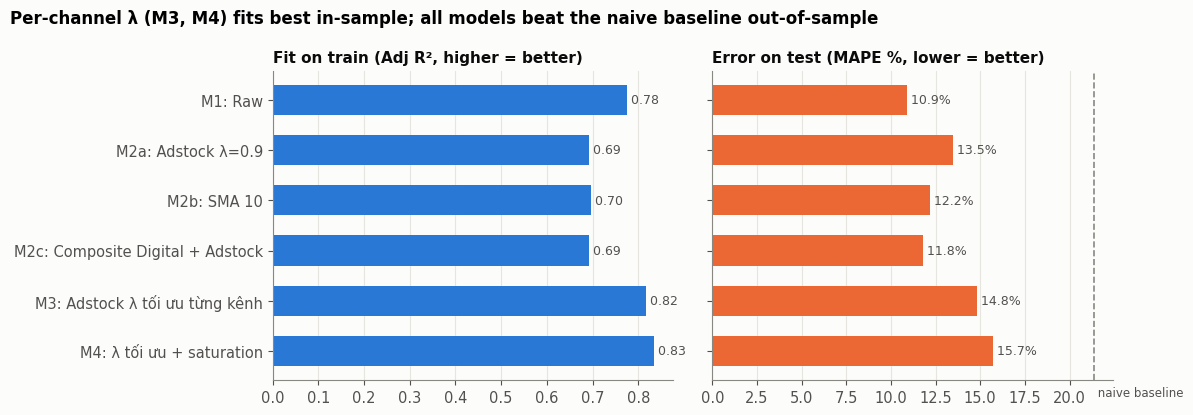

In [ ]:
results = pd.DataFrame([r1, r2a, r2b, r2c, r3, r4]).set_index('Model')
display(results.round(2))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
order = results.index[::-1]
for ax, col, title, colr in [(axs[0], 'Adj R² (train)', 'Fit on train (Adj R², higher = better)', C[0]),
                             (axs[1], 'MAPE test %', 'Error on test (MAPE %, lower = better)', C[1])]:
    vals = results.loc[order, col]
    ax.barh(order, vals, color=colr, height=0.6)
    for i, v in enumerate(vals):
        ax.text(v, i, f' {v:.2f}' if col.startswith('Adj') else f' {v:.1f}%',
                va='center', fontsize=9, color=INK2)
    ax.set_title(title, fontsize=11); ax.grid(axis='y', visible=False)
axs[1].axvline(naive_mean, color=MUTED, ls='--', lw=1.2)
axs[1].text(naive_mean, -0.9, ' naive baseline', color=INK2, fontsize=8.5)
axs[1].set_yticklabels([])
fig.suptitle('Per-channel λ (M3, M4) fits best in-sample; all models beat the naive baseline out-of-sample',
             x=0.01, ha='left', fontweight='bold', fontsize=12)
save(fig, '13_model_scorecard')

### 📝 Findings — So sánh mô hình & chọn mô hình cuối
- **M3 khớp train tốt nhất** trong các mô hình tuyến tính: Adj R² **0.82**, AIC **1,920**, **0 hệ số media âm**, VIF **7.7** (< 10).
- **Nghịch lý:** M3 có MAPE test **14.8%**, cao hơn M1 (10.9%). Bias test **+608** → M3 dự đoán **thấp hơn thực tế** suốt giai đoạn test.
  - Giai đoạn test: Meta bị cắt từ 5–8 triệu xuống ~1 triệu impressions/tuần, click Brand Search giảm ~40%, nhưng **số đăng ký gần như không giảm**.
  - M3 gán nhiều công cho media hơn → kỳ vọng đăng ký giảm mạnh hơn → sai nhiều hơn.
  - → **Phát hiện:** dữ liệu 2022 gợi ý hiệu quả thật của Meta/Brand Search **thấp hơn** những gì dữ liệu 2019–2021 cho thấy.
- **Chọn M3** vì mục tiêu của MMM là **phân bổ công lao**: M3 là mô hình duy nhất vừa có dấu hệ số hợp lý, vừa phản ánh hiệu ứng trễ đã quan sát ở EDA, vừa ổn định (tối ưu lại λ trên toàn bộ 152 tuần cho kết quả gần như giống hệt). MAPE test 14.8% vẫn tốt hơn nhiều so với baseline 21.4%.
- **M4** giữ làm **phân tích độ nhạy** cho kịch bản dự báo (hiệu suất giảm dần).

## 6. Final model (M3, refit on 152 weeks)

Durbin-Watson (phần dư): 0.88   (≈2 là tốt; <1.5 là tự tương quan dương)
                            OLS Regression Results                            
Dep. Variable:                   Subs   R-squared:                       0.801
Model:                            OLS   Adj. R-squared:                  0.786
No. Observations:                 152   F-statistic:                     44.37
Covariance Type:                  HAC   Prob (F-statistic):           1.54e-38
                                                   coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
const                                         3423.9266    315.300     10.859      0.000    2805.950    4041.903
Google_Display_Impressions_AdOpt                 0.0014      0.001      1.791      0.073      -0.000       0.003
Meta_Impressions_AdOpt                        5.653e-05   2.53e-05      2.235   

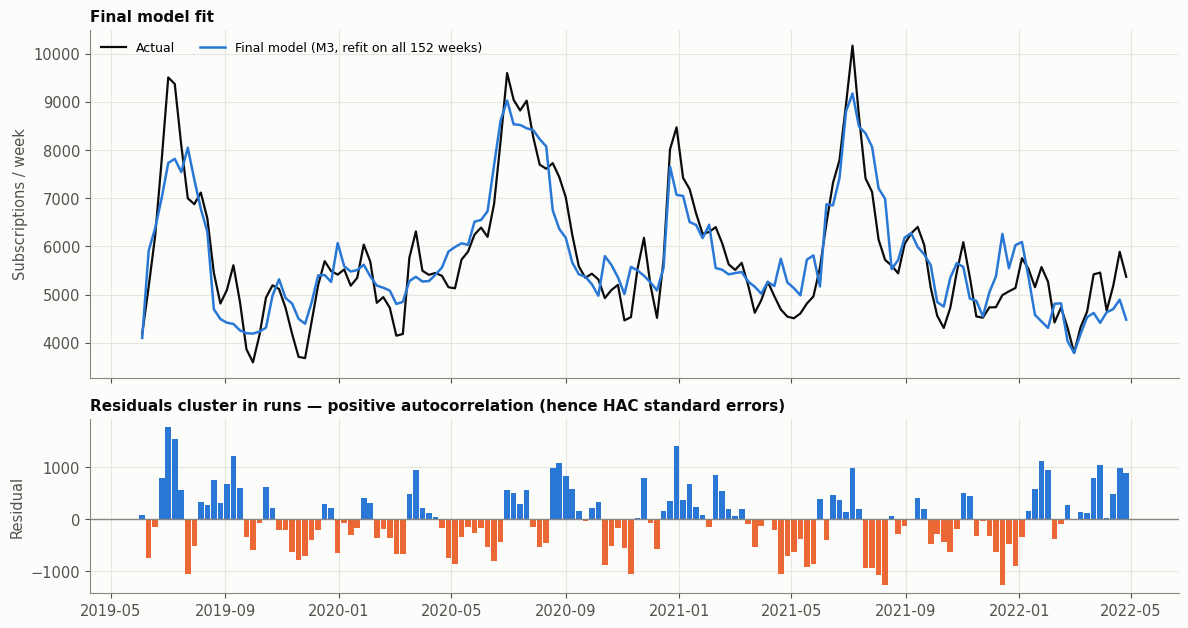

In [ ]:
from statsmodels.stats.stattools import durbin_watson

FINAL_MEDIA = [f'{m}_AdOpt' for m in MEDIA]
X_full = sm.add_constant(feat[FINAL_MEDIA + CONTROLS], has_constant='add')
final_ols = sm.OLS(feat.Subs, X_full).fit()
final = sm.OLS(feat.Subs, X_full).fit(cov_type='HAC', cov_kwds={'maxlags': 4})

print(f'Durbin-Watson (phần dư): {durbin_watson(final_ols.resid):.2f}   (≈2 là tốt; <1.5 là tự tương quan dương)')
print(final.summary(slim=True))
fitted = final.fittedvalues
print(f'Full data — Adj R²: {final_ols.rsquared_adj:.3f} | MAPE: {mean_absolute_percentage_error(feat.Subs, fitted)*100:.2f}%')

fig, axs = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True, gridspec_kw={'height_ratios': [2, 1]})
axs[0].plot(feat.Date, feat.Subs, color=INK, lw=1.6, label='Actual')
axs[0].plot(feat.Date, fitted, color=C[0], lw=1.8, label='Final model (M3, refit on all 152 weeks)')
axs[0].legend(loc='upper left', ncol=2, fontsize=9); axs[0].set_ylabel('Subscriptions / week')
axs[0].set_title('Final model fit', fontsize=11)
resid = feat.Subs - fitted
axs[1].bar(feat.Date, resid, width=6, color=np.where(resid >= 0, C[0], C[1]))
axs[1].axhline(0, color=MUTED, lw=1); axs[1].set_ylabel('Residual')
axs[1].set_title('Residuals cluster in runs — positive autocorrelation (hence HAC standard errors)', fontsize=11)
save(fig, '14_final_fit_residuals')

### 📝 Findings — Mô hình cuối (M3, fit lại trên 152 tuần)
- Adj R² **0.786**, MAPE **8.5%** trên toàn bộ dữ liệu.
- **Durbin-Watson = 0.88** (< 1.5) → phần dư **tự tương quan dương**: mô hình sai theo từng "đợt" nhiều tuần liền (xem biểu đồ phần dư). → Dùng **sai số chuẩn HAC (Newey-West)** để p-value không bị lạc quan quá mức.
- **Hệ số sau khi thêm 30 tuần cuối:** β Meta giảm **37%** (8.9e-05 → 5.65e-05), β TV giảm **21%** (0.199 → 0.158) → dữ liệu 2022 đã "kéo" ước lượng về mức thận trọng hơn, đúng như nghịch lý ở tập test gợi ý.
- **Ý nghĩa thống kê (HAC):**
  - Rất chắc chắn (p < 0.01): **Generic Search, TV, YouTube**, Comp_Promo.
  - Chắc chắn (p < 0.05): **Meta**, Summer_Holiday, Promotion.
  - Biên (0.05 < p < 0.10): **Brand Search** (0.076), **Display** (0.073).
  - Không có ý nghĩa: **Influencers** (p = 0.20) → mọi kết luận về Influencers đều **không đáng tin**.
- **Biến kiểm soát:** tuần nghỉ hè +963 đăng ký; mỗi đơn vị khuyến mãi công ty +41; mỗi đơn vị khuyến mãi đối thủ **−69** (≈ −1,110 đăng ký/tuần khi đối thủ chuyển từ 14 lên 30).

Breusch-Pagan  p = 0.057   → phương sai đều (đạt)
Jarque-Bera    p = 0.323   → phân phối chuẩn (đạt)
Tự tương quan lag 1 = 0.55
Ljung-Box p-value theo độ trễ:
1   0.00
2   0.00
4   0.00
8   0.00


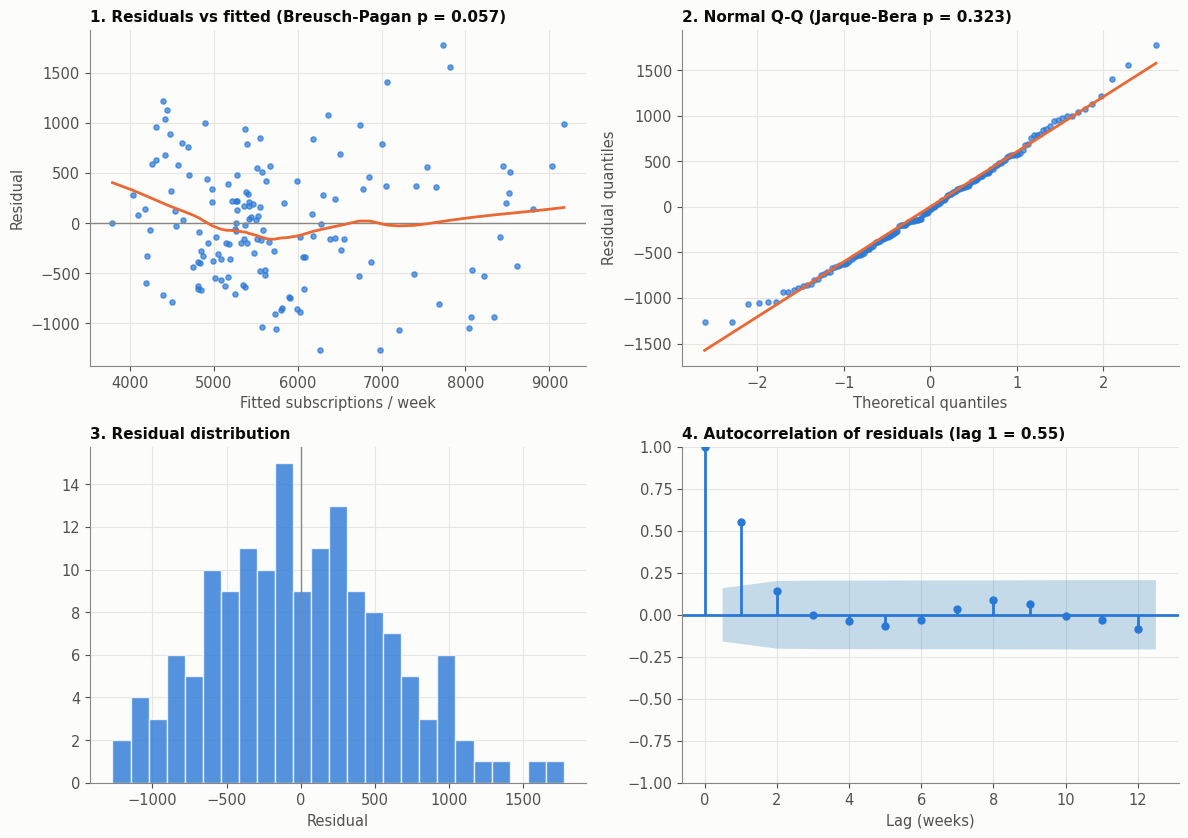

In [ ]:
# ===== Kiểm tra giả định OLS trên phần dư của mô hình cuối =====
from statsmodels.stats.diagnostic import het_breuschpagan, acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera
from statsmodels.graphics.tsaplots import plot_acf
import scipy.stats as st

res, fit_v = final_ols.resid, final_ols.fittedvalues

# 1) Ba kiểm định
bp_p = het_breuschpagan(res, X_full)[1]                       # phương sai có đều không
jb_p = jarque_bera(res)[1]                                    # phần dư có phân phối chuẩn không
lb   = acorr_ljungbox(res, lags=[1, 2, 4, 8], return_df=True) # sai số tuần này có kéo tuần sau không
acf1 = res.autocorr(lag=1)

print(f'Breusch-Pagan  p = {bp_p:.3f}   → ' + ('phương sai đều (đạt)' if bp_p > 0.05 else 'phương sai KHÔNG đều'))
print(f'Jarque-Bera    p = {jb_p:.3f}   → ' + ('phân phối chuẩn (đạt)' if jb_p > 0.05 else 'KHÔNG chuẩn'))
print(f'Tự tương quan lag 1 = {acf1:.2f}')
print('Ljung-Box p-value theo độ trễ:'); print(lb['lb_pvalue'].round(4).to_string())

# 2) Bốn biểu đồ chẩn đoán
fig, axs = plt.subplots(2, 2, figsize=(12, 8.5))

ax = axs[0, 0]
ax.scatter(fit_v, res, s=14, color=C[0], alpha=0.7)
ax.axhline(0, color=MUTED, lw=1)
low = sm.nonparametric.lowess(res, fit_v, frac=0.6)
ax.plot(low[:, 0], low[:, 1], color=C[1], lw=2)
ax.set_title(f'1. Residuals vs fitted (Breusch-Pagan p = {bp_p:.3f})', fontsize=11)
ax.set_xlabel('Fitted subscriptions / week'); ax.set_ylabel('Residual')

ax = axs[0, 1]
(osm, osr), (slope, intercept, _) = st.probplot(res, dist='norm')
ax.scatter(osm, osr, s=14, color=C[0], alpha=0.7)
ax.plot(osm, slope * osm + intercept, color=C[1], lw=2)
ax.set_title(f'2. Normal Q-Q (Jarque-Bera p = {jb_p:.3f})', fontsize=11)
ax.set_xlabel('Theoretical quantiles'); ax.set_ylabel('Residual quantiles')

ax = axs[1, 0]
ax.hist(res, bins=25, color=C[0], alpha=0.8, edgecolor=SURF)
ax.axvline(0, color=MUTED, lw=1)
ax.set_title('3. Residual distribution', fontsize=11); ax.set_xlabel('Residual')

ax = axs[1, 1]
plot_acf(res, lags=12, ax=ax, color=C[0], vlines_kwargs={'colors': C[0]})
ax.set_title(f'4. Autocorrelation of residuals (lag 1 = {acf1:.2f})', fontsize=11)
ax.set_xlabel('Lag (weeks)')

save(fig, '18_residual_diagnostics')

### 📝 Findings — Kiểm tra giả định OLS trên phần dư

| Giả định | Kiểm định | Kết quả | Kết luận |
|---|---|---|---|
| Phương sai đều | Breusch-Pagan | p = 0.057 | **Đạt** (sát ngưỡng): đường xu hướng hơi cong ở vùng dự đoán thấp → mô hình hơi đoán thấp các tuần thấp điểm |
| Phân phối chuẩn | Jarque-Bera | p = 0.323 | **Đạt**: các điểm bám sát đường thẳng trên Q-Q plot |
| Các tuần độc lập | Ljung-Box, ACF | lag 1 = 0.55, p ≈ 0 | **Không đạt**: sai số tuần này kéo theo tuần sau; từ lag 2 trở đi nằm trong vùng tin cậy |

- **Giả định duy nhất bị vi phạm là tự tương quan**, và chỉ ở độ trễ 1 tuần → sai số chuẩn **HAC (Newey-West, 4 lags)** đã dùng ở mô hình cuối là cách xử lý phù hợp.
- Tự tương quan **không làm lệch hệ số β** → đóng góp từng kênh và ROI vẫn đúng; nó chỉ làm p-value thông thường quá lạc quan, và HAC đã sửa phần đó.
- → Mô hình đủ tin cậy để dùng cho

## 7. Contribution, revenue & ROI

In [ ]:
PRICE = 35
b = final.params
total_subs = feat.Subs.sum()

# (1) Media: β × tổng giá trị biến (đã adstock) trên toàn bộ dữ liệu — đúng công thức đề bài
media_contrib = pd.Series({m: b[f'{m}_AdOpt'] * feat[f'{m}_AdOpt'].sum() for m in MEDIA})

# (2) Phần không phải media — đo so với mức "bình thường" (khuyến mãi 14, không nghỉ)
REF = {'Full_Holiday': 0, 'Summer_Holiday': 0, 'Promotion': 14, 'Comp_Promo': 14}
base_week = b['const'] + sum(b[c] * REF[c] for c in CONTROLS)
other_contrib = pd.Series({
    'Base (không quảng cáo, KM mức 14)': base_week * len(feat),
    'Kỳ nghỉ trọn': b['Full_Holiday'] * feat.Full_Holiday.sum(),
    'Phần cộng thêm mùa hè': b['Summer_Holiday'] * feat.Summer_Holiday.sum(),
    'KM công ty lên mức 30': b['Promotion'] * (feat.Promotion - 14).sum(),
    'KM đối thủ lên mức 30': b['Comp_Promo'] * (feat.Comp_Promo - 14).sum(),
})
decomp = pd.concat([other_contrib, media_contrib.rename(SHORT)])
decomp_tbl = pd.DataFrame({'Số đăng ký': decomp, '% tổng': decomp / total_subs * 100})
display(decomp_tbl.round(1))
print(f'Kiểm tra: tổng các phần = {decomp.sum():,.0f} | tổng thực tế = {total_subs:,.0f}')
print(f'Media tạo ra {media_contrib.sum():,.0f} đăng ký = {media_contrib.sum()/total_subs:.1%} tổng số')

,Số đăng ký,% tổng
"Base (không quảng cáo, KM mức 14)","460,009.20",52.30
Kỳ nghỉ trọn,"13,516.40",1.50
Phần cộng thêm mùa hè,"27,915.20",3.20
KM công ty lên mức 30,"31,359.80",3.60
KM đối thủ lên mức 30,"-53,209.10",-6.00
Google Display,"6,205.50",0.70
Meta,"60,173.80",6.80
Google Generic Search,"132,880.50",15.10
TV,"29,312.00",3.30
Influencers,"17,538.00",2.00


Kiểm tra: tổng các phần = 879,741 | tổng thực tế = 879,742
Media tạo ra 400,150 đăng ký = 45.5% tổng số


### 📝 Findings — Phân rã số đăng ký (06/2019 → 04/2022, tổng 879,742)
- **Base: 52.3%** (~3,026 đăng ký/tuần) — số người sẽ đăng ký dù không có quảng cáo, ở mức khuyến mãi thông thường (14).
- **Media: 45.5%** (~400,150 đăng ký) — gần một nửa số đăng ký nhờ quảng cáo.
- **Mùa vụ: +4.7%** (nghỉ trọn +1.5%, phần cộng thêm mùa hè +3.2%).
- **Khuyến mãi công ty lên mức 30: +3.6%** (~31,400 đăng ký).
- **Khuyến mãi đối thủ lên mức 30: −6.0%** (~−53,200 đăng ký) → mất nhiều hơn những gì khuyến mãi của công ty mang lại. Từ T6/2021, đối thủ ở mức 30 liên tục → mỗi tuần mất ~1,100 đăng ký.
- **Thứ tự đóng góp của media:** Generic Search **15.1%** > Brand Search **10.6%** > YouTube **6.9%** ≈ Meta **6.8%** > TV **3.3%** > Influencers 2.0% > Display 0.7%.
- *Phương pháp:* đóng góp media = β × tổng adstock (công thức đề bài). Khuyến mãi được đo **so với mức 14** (mức thấp nhất từng xảy ra), không phải so với 0 — vì "không có khuyến mãi" chưa từng xuất hiện trong dữ liệu. Tổng các phần = đúng tổng thực tế (879,742) ✓.

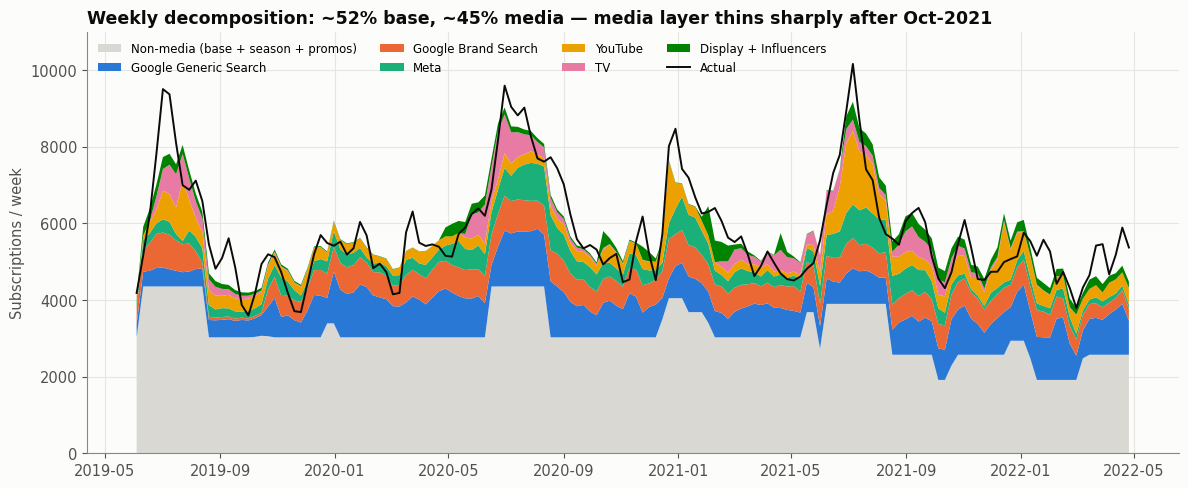

In [ ]:
grp = {'Google Generic Search': ['Google_Generic_Paid_Search_Impressions'],
       'Google Brand Search': ['Google_Brand_Paid_Search_Clicks'],
       'Meta': ['Meta_Impressions'], 'YouTube': ['YouTube_Impressions'], 'TV': ['TV_GRP'],
       'Display + Influencers': ['Google_Display_Impressions', 'Influencers_Views']}
weekly = pd.DataFrame({g: sum(b[f'{m}_AdOpt'] * feat[f'{m}_AdOpt'] for m in ms) for g, ms in grp.items()})
weekly.insert(0, 'Non-media (base + season + promos)', fitted - weekly.sum(axis=1))

fig, ax = plt.subplots(figsize=(12, 5))
ax.stackplot(feat.Date, weekly.T.values, labels=weekly.columns, colors=['#d9d8d3'] + C[:6], lw=0)
ax.plot(feat.Date, feat.Subs, color=INK, lw=1.4, label='Actual')
ax.set_ylabel('Subscriptions / week'); ax.set_ylim(0, 11000)
ax.legend(loc='upper left', ncol=4, fontsize=8.5)
ax.set_title('Weekly decomposition: ~52% base, ~45% media — media layer thins sharply after Oct-2021')
save(fig, '15_decomposition_weekly')

### 📝 Findings — Phân rã theo tuần
- Đỉnh mùa hè đến từ **cả hai**: base/mùa vụ tăng và media được đẩy mạnh (Meta, YouTube, TV dồn vào T6–T8).
- **Từ T10/2021, lớp media mỏng đi rõ rệt** (Meta bị cắt, TV gần như dừng) → phần lớn số đăng ký 2022 do base và Generic Search giữ lại.
- Tuy vậy, số đăng ký thực tế 2022 vẫn **cao hơn** mô hình dự đoán (vùng đường đen vượt lên trên) → thêm bằng chứng rằng mô hình có thể **đánh giá cao** tác động của các kênh bị cắt.

In [ ]:
spend_total = pd.Series({m: spend[SPEND_MAP[m]].sum() for m in MEDIA})
roi = pd.DataFrame({
    'Đăng ký từ media': media_contrib,
    '% đăng ký': media_contrib / total_subs * 100,
    'Doanh thu ($)': media_contrib * PRICE,
    'Chi phí': spend_total,
    '% ngân sách': spend_total / spend_total.sum() * 100,
    'ROI': media_contrib * PRICE / spend_total,
    'Chi phí / đăng ký (CPA)': spend_total / media_contrib,
    'p-value (HAC)': [final.pvalues[f'{m}_AdOpt'] for m in MEDIA],
})
roi.index = [SHORT[m] for m in MEDIA]
roi = roi.sort_values('ROI', ascending=False)
roi.loc['TỔNG MEDIA'] = [media_contrib.sum(), media_contrib.sum() / total_subs * 100,
                         media_contrib.sum() * PRICE, spend_total.sum(), 100,
                         media_contrib.sum() * PRICE / spend_total.sum(),
                         spend_total.sum() / media_contrib.sum(), np.nan]
display(roi.style.format({'Đăng ký từ media': '{:,.0f}', '% đăng ký': '{:.1f}', 'Doanh thu ($)': '{:,.0f}',
                          'Chi phí': '{:,.0f}', '% ngân sách': '{:.1f}', 'ROI': '{:.3f}',
                          'Chi phí / đăng ký (CPA)': '{:,.1f}', 'p-value (HAC)': '{:.3f}'}))

,Đăng ký từ media,% đăng ký,Doanh thu ($),Chi phí,% ngân sách,ROI,Chi phí / đăng ký (CPA),p-value (HAC)
Influencers,"17,538",2.0,"613,831","17,142",0.0,35.809,1.0,0.200
YouTube,"60,802",6.9,"2,128,060","972,324",0.7,2.189,16.0,0.000
Google Brand Search,"93,238",10.6,"3,263,344","1,733,241",1.3,1.883,18.6,0.076
Google Display,"6,205",0.7,"217,191","251,979",0.2,0.862,40.6,0.073
Google Generic Search,"132,881",15.1,"4,650,818","25,161,023",19.0,0.185,189.4,0.000
Meta,"60,174",6.8,"2,106,085","35,761,611",27.0,0.059,594.3,0.025
TV,"29,312",3.3,"1,025,922","68,688,903",51.8,0.015,"2,343.4",0.003
TỔNG MEDIA,"400,150",45.5,"14,005,250","132,586,224",100.0,0.106,331.3,nan


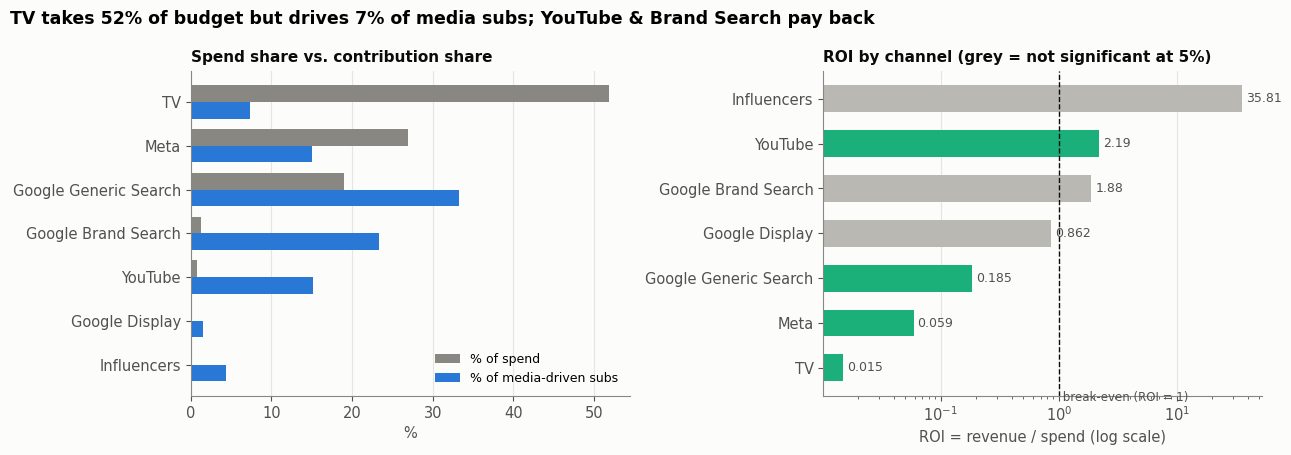

In [ ]:
r = roi.drop('TỔNG MEDIA')
fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))

order = r.sort_values('% ngân sách').index
y = np.arange(len(order)); h = 0.38
axs[0].barh(y + h/2, r.loc[order, '% ngân sách'], h, color=MUTED, label='% of spend')
axs[0].barh(y - h/2, r.loc[order, '% đăng ký'] / r['% đăng ký'].sum() * 100, h, color=C[0],
            label='% of media-driven subs')
axs[0].set_yticks(y); axs[0].set_yticklabels(order); axs[0].grid(axis='y', visible=False)
axs[0].legend(loc='lower right', fontsize=9); axs[0].set_xlabel('%')
axs[0].set_title('Spend share vs. contribution share', fontsize=11)

o2 = r.sort_values('ROI').index
colors = [C[2] if p <= 0.05 else '#b9b8b2' for p in r.loc[o2, 'p-value (HAC)']]
axs[1].barh(o2, r.loc[o2, 'ROI'], color=colors, height=0.6)
axs[1].set_xscale('log'); axs[1].axvline(1, color=INK, lw=1, ls='--')
axs[1].text(1, -0.75, ' break-even (ROI = 1)', fontsize=8.5, color=INK2)
for i, v in enumerate(r.loc[o2, 'ROI']):
    axs[1].text(v * 1.08, i, f'{v:.3f}' if v < 1 else f'{v:.2f}', va='center', fontsize=9, color=INK2)
axs[1].grid(axis='y', visible=False); axs[1].set_xlabel('ROI = revenue / spend (log scale)')
axs[1].set_title('ROI by channel (grey = not significant at 5%)', fontsize=11)
fig.suptitle('TV takes 52% of budget but drives 7% of media subs; YouTube & Brand Search pay back',
             x=0.01, ha='left', fontweight='bold', fontsize=12.5)
save(fig, '16_spend_vs_contribution_roi')

### 📝 Findings — Revenue & ROI

**Ngân sách và hiệu quả lệch nhau nghiêm trọng:**

| Kênh | % ngân sách | % đăng ký từ media | ROI | Chi phí / đăng ký | p (HAC) |
|---|---|---|---|---|---|
| TV | **51.8%** | 7.3% | **0.015** | **2,343** | 0.003 |
| Meta | 27.0% | 15.0% | 0.059 | 594 | 0.025 |
| Generic Search | 19.0% | 33.2% | 0.185 | 189 | <0.001 |
| Brand Search | 1.3% | 23.3% | 1.88 | 18.6 | 0.076 |
| YouTube | **0.7%** | **15.2%** | **2.19** | **16.0** | <0.001 |
| Display | 0.2% | 1.6% | 0.86 | 40.6 | 0.073 |
| Influencers | 0.01% | 4.4% | 35.8 | 1.0 | **0.200** |

- **Tổng media:** doanh thu **$14.0M** trên chi phí** 132.6M** → ROI **0.106**. Như đã ghi ở Bước 0: ROI < 1 cho cả hệ thống gợi ý chi phí có thể tính bằng **đơn vị tiền tệ khác USD** → nên đọc ROI theo **thứ hạng tương đối** giữa các kênh.
- **YouTube là kênh hiệu quả nhất có ý nghĩa thống kê:** chỉ 0.7% ngân sách nhưng tạo 15% số đăng ký từ media, ROI 2.19, chi phí ~$16/đăng ký (< giá $35).
- **TV kém hiệu quả nhất:** 52% ngân sách, chi phí ~2,343/đăng ký — gấp **~67 lần** giá một tài khoản.
- **Meta** chiếm 27% ngân sách nhưng ROI chỉ 0.059.

**⚠️ 5 lưu ý trước khi biến ROI thành quyết định ngân sách:**
1. **ROI trung bình ≠ ROI biên.** ROI 2.19 của YouTube đo ở quy mô *hiện tại* (rất nhỏ). Tăng ngân sách gấp nhiều lần, hiệu suất có thể giảm (saturation) → cần tăng từ từ và đo lại.
2. **Brand Search có thể bị thổi phồng:** người tìm "Book-Worm" thường đã biết thương hiệu nhờ kênh khác (TV, Meta). Brand Search "thu hoạch" nhu cầu do kênh khác tạo ra → một phần công của nó thuộc về các kênh phía trên phễu.
3. **TV có thể bị đánh giá thấp:** (a) tác động xây dựng thương hiệu dài hạn vượt quá λ = 0.8 khó đo trong 3 năm dữ liệu; (b) TV góp phần tạo ra lượt tìm kiếm thương hiệu (điểm 2); (c) ~12.9 triệu chi phí TV rơi vào các tuần không có GRP.
4. **Influencers:** ROI 35.8 **không đáng tin** — hệ số không có ý nghĩa thống kê (p = 0.20), và dữ liệu có dấu hiệu lặp lại/mô phỏng.
5. **Brand Search và Display chỉ có ý nghĩa ở mức biên** (p ≈ 0.07–0.08).

## 8. Scenario: doubling Meta & YouTube (May–Dec 2022)

In [ ]:
scen = pred[pred.Date > sales.Date.max()].reset_index(drop=True)      # bỏ tuần 26/04/2022 bị trùng
print(f'Kịch bản: {scen.Date.min().date()} → {scen.Date.max().date()} ({len(scen)} tuần)')

def build_scenario(p, lams=None, sats=None):
    """Nối lịch sử + kịch bản → tính adstock trên chuỗi liền mạch → trả về phần kịch bản."""
    lams = lams or LAM_OPT
    full = pd.concat([sales.drop(columns='Subs'), p], ignore_index=True)
    mm = media_matrix(full, lams, sats)
    for m in MEDIA:
        full[f'{m}_AdOpt'] = mm[m]
    full['Full_Holiday'] = (full.Holiday >= 5).astype(int)
    full['Summer_Holiday'] = ((full.Holiday >= 5) & full.Date.dt.month.isin([6, 7, 8])).astype(int)
    return full.iloc[len(sales):].reset_index(drop=True)

scen_base = scen.copy()                                    # đối chứng: Meta & YouTube giữ mức 2021
scen_base[['Meta_Impressions', 'YouTube_Impressions']] /= 2

S_double, S_base = build_scenario(scen), build_scenario(scen_base)

# Kiểm tra: kịch bản gấp đôi đúng bằng 2× đối chứng ở Meta & YouTube, các biến khác giống hệt
display((S_double[MEDIA] / S_base[MEDIA].replace(0, np.nan)).agg(['min', 'max']).round(2).T.rename(index=SHORT))

Kịch bản: 2022-05-03 → 2022-12-20 (34 tuần)


,min,max
Google Display,1.00,1.00
Meta,2.00,2.00
Google Generic Search,1.00,1.00
TV,1.00,1.00
Influencers,1.00,1.00
Google Brand Search,1.00,1.00
YouTube,2.00,2.00


In [ ]:
def decompose(S):
    X = sm.add_constant(S[FINAL_MEDIA + CONTROLS], has_constant='add')
    parts = {SHORT[m]: final.params[f'{m}_AdOpt'] * S[f'{m}_AdOpt'] for m in MEDIA}
    parts['Non-media'] = final.predict(X) - sum(parts.values())
    return pd.DataFrame(parts), final.predict(X)

parts_d, pred_d = decompose(S_double)
parts_b, pred_b = decompose(S_base)

same_2021 = sales[(sales.Date >= '2021-05-04') & (sales.Date <= '2021-12-21')]
summary = pd.DataFrame({'Đối chứng (mức 2021)': parts_b.sum(), 'Gấp đôi Meta & YouTube': parts_d.sum()})
summary.loc['TỔNG DỰ BÁO'] = [pred_b.sum(), pred_d.sum()]
summary['Chênh lệch'] = summary.iloc[:, 1] - summary.iloc[:, 0]
display(summary.round(0))
print(f'Thực tế cùng kỳ 2021: {same_2021.Subs.sum():,.0f} | mô hình fit cùng kỳ 2021: '
      f'{final.fittedvalues[same_2021.index].sum():,.0f}')
inc = pred_d.sum() - pred_b.sum()
print(f'→ Gấp đôi Meta & YouTube: +{inc:,.0f} đăng ký trong {len(scen)} tuần (+{inc/pred_b.sum():.1%})')

,Đối chứng (mức 2021),Gấp đôi Meta & YouTube,Chênh lệch
Google Display,708.00,708.00,0.00
Meta,"16,316.00","32,525.00","16,210.00"
Google Generic Search,"28,241.00","28,241.00",0.00
TV,"8,419.00","8,419.00",0.00
Influencers,"7,920.00","7,920.00",0.00
Google Brand Search,"21,888.00","21,888.00",0.00
YouTube,"22,010.00","43,912.00","21,902.00"
Non-media,"102,788.00","102,788.00",0.00
TỔNG DỰ BÁO,"208,289.00","246,401.00","38,112.00"


Thực tế cùng kỳ 2021: 200,318 | mô hình fit cùng kỳ 2021: 208,923
→ Gấp đôi Meta & YouTube: +38,112 đăng ký trong 34 tuần (+18.3%)


### 📝 Findings — Kịch bản gấp đôi Meta & YouTube (03/05 → 20/12/2022, 34 tuần)
- **Đối chứng** (Meta & YouTube giữ mức 2021): **208,289** đăng ký.
- **Gấp đôi Meta & YouTube:** **246,401** đăng ký → **+38,112 (+18.3%)**, trung bình **~1,120 đăng ký/tuần**.
- Toàn bộ chênh lệch đến từ 2 kênh được tăng — các kênh khác và phần non-media **giống hệt** nhau ở hai kịch bản (đúng thiết kế thí nghiệm có kiểm soát).
- Mô hình **ước lượng cao hơn thực tế ~4.3%** ở cùng kỳ 2021 (208,923 so với 200,318) → **con số tuyệt đối** 246,401 có thể cao hơn thực tế ~4%. Nhưng **phần tăng thêm** (+38,112) không bị ảnh hưởng, vì sai số này xuất hiện như nhau ở cả hai kịch bản và triệt tiêu khi trừ.

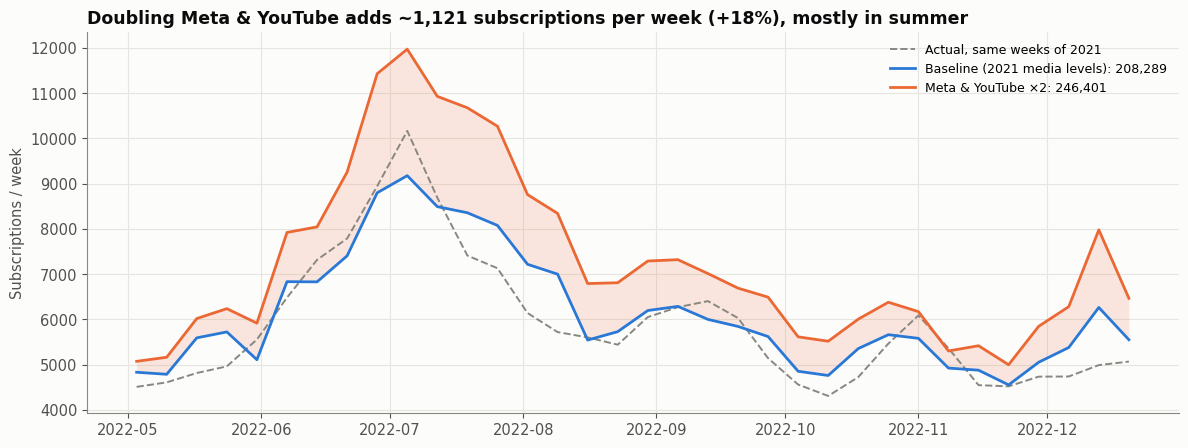

In [ ]:
fig, ax = plt.subplots(figsize=(12, 4.6))
ax.plot(scen.Date, same_2021.Subs.values, color=MUTED, lw=1.4, ls='--', label='Actual, same weeks of 2021')
ax.plot(scen.Date, pred_b, color=C[0], lw=2, label=f'Baseline (2021 media levels): {pred_b.sum():,.0f}')
ax.plot(scen.Date, pred_d, color=C[1], lw=2, label=f'Meta & YouTube ×2: {pred_d.sum():,.0f}')
ax.fill_between(scen.Date, pred_b, pred_d, color=C[1], alpha=0.15, lw=0)
ax.set_ylabel('Subscriptions / week'); ax.legend(loc='upper right', fontsize=9)
ax.set_title(f'Doubling Meta & YouTube adds ~{inc/len(scen):,.0f} subscriptions per week '
             f'(+{inc/pred_b.sum():.0%}), mostly in summer')
save(fig, '17_scenario_weekly')

### 📝 Findings — Phân bố theo tuần
- Phần tăng thêm **tập trung vào mùa hè (T6–T8)** và **giữa T12** — đúng những tuần năm 2021 công ty chạy Meta/YouTube mạnh nhất. Gấp đôi một mức vốn đã cao thì phần tăng tuyệt đối cũng lớn nhất.
- Các tuần T9–T11 (Meta và YouTube vốn chạy ít) gần như không đổi.

In [ ]:
sp21 = spend[(spend.Date >= '2021-05-04') & (spend.Date <= '2021-12-21')]
rows = {}
for m, cost in [('Meta_Impressions', 'Meta Cost'), ('YouTube_Impressions', 'YouTube Cost')]:
    d_subs = parts_d[SHORT[m]].sum() - parts_b[SHORT[m]].sum()
    d_cost = sp21[cost].sum()                      # gấp đôi hoạt động ⇒ chi thêm đúng bằng mức 2021
    rows[SHORT[m]] = [d_subs, d_subs * PRICE, d_cost, d_subs * PRICE / d_cost, d_cost / d_subs]
tot_cost = sp21[['Meta Cost', 'YouTube Cost']].sum().sum()
rows['Tổng'] = [inc, inc * PRICE, tot_cost, inc * PRICE / tot_cost, tot_cost / inc]
incr = pd.DataFrame(rows, index=['Đăng ký tăng thêm', 'Doanh thu tăng thêm ($)', 'Chi phí tăng thêm',
                                 'ROI gia tăng', 'Chi phí / đăng ký tăng thêm']).T
display(incr.style.format('{:,.2f}'))

# Độ nhạy: mô hình có hiệu suất giảm dần (M4), fit lại trên toàn bộ dữ liệu
X4 = sm.add_constant(pd.concat([media_matrix(feat, LAM_SAT, SAT_SAT), feat[CONTROLS]], axis=1),
                     has_constant='add')
m4_full = sm.OLS(feat.Subs, X4).fit()

def predict_m4(p):
    full = pd.concat([sales.drop(columns='Subs'), p], ignore_index=True)
    full['Full_Holiday'] = (full.Holiday >= 5).astype(int)
    full['Summer_Holiday'] = ((full.Holiday >= 5) & full.Date.dt.month.isin([6, 7, 8])).astype(int)
    X = sm.add_constant(pd.concat([media_matrix(full, LAM_SAT, SAT_SAT), full[CONTROLS]], axis=1),
                        has_constant='add')
    return m4_full.predict(X).iloc[len(sales):]

inc4 = predict_m4(scen).sum() - predict_m4(scen_base).sum()
print(f'Độ nhạy — M4 (saturation): +{inc4:,.0f} đăng ký (+{inc4/predict_m4(scen_base).sum():.1%}), '
      f'ROI gia tăng {inc4*PRICE/tot_cost:.3f}')

,Đăng ký tăng thêm,Doanh thu tăng thêm ($),Chi phí tăng thêm,ROI gia tăng,Chi phí / đăng ký tăng thêm
Meta,"16,209.57","567,334.78","12,775,357.97",0.04,788.14
YouTube,"21,902.44","766,585.27","352,753.74",2.17,16.11
Tổng,"38,112.00","1,333,920.05","13,128,111.71",0.10,344.46


Độ nhạy — M4 (saturation): +30,055 đăng ký (+14.4%), ROI gia tăng 0.080


### 📝 Findings — Tác động & ROI gia tăng: Meta và YouTube là hai quyết định hoàn toàn khác nhau

| | Đăng ký tăng thêm | Chi phí tăng thêm | ROI gia tăng | Chi phí / đăng ký thêm |
|---|---|---|---|---|
| **YouTube** | **+21,902** (57% phần tăng) | 0.35M (**2.7%** chi phí thêm) | **2.17** | **$16** (< giá $35) |
| **Meta** | +16,210 (43%) | 12.78M (**97.3%**) | 0.044 | **788** (≈ 22 lần giá $35) |
| Tổng | +38,112 | 13.13M | 0.10 | 344 |

- **YouTube** mang lại **hơn một nửa** số đăng ký tăng thêm với chưa đến 3% chi phí tăng thêm → **có lãi** ngay cả theo mô hình thận trọng.
- **Meta** chiếm gần như toàn bộ chi phí tăng thêm nhưng mỗi đăng ký mới tốn ~788 → **lỗ nặng**.
- **Độ nhạy (M4 — hiệu suất giảm dần):** +30,055 đăng ký (+14.4%), ROI gia tăng 0.080 → mô hình tuyến tính M3 là **cận trên**; con số thật nhiều khả năng nằm trong khoảng **+30,000 đến +38,000**.
- **Thêm một lý do để thận trọng với Meta:** khi Meta bị cắt mạnh ở 2022, số đăng ký không giảm như mô hình dự đoán (Bước 3) → hiệu quả thật của Meta có thể còn **thấp hơn** ước lượng.
- → **Kết luận:** đề bài gộp hai kênh thành một quyết định, nhưng dữ liệu cho thấy nên **tách ra**: tăng YouTube (từng bước, đo lại sau mỗi đợt), **không** tăng Meta.

## 9. Summary & recommendations (Tổng kết & Khuyến nghị)

### Kết quả chính
1. **52% số đăng ký là base** (tự đến), **45.5% nhờ media**, phần còn lại do mùa vụ và khuyến mãi.
2. **Ngân sách lệch khỏi hiệu quả:** TV chiếm 52% ngân sách nhưng chỉ tạo ~7% số đăng ký từ media; YouTube chiếm 0.7% ngân sách nhưng tạo ~15%.
3. **Kênh hiệu quả nhất** (có ý nghĩa thống kê): **YouTube** (ROI 2.19, ~$16/đăng ký). **Kém nhất:** **TV** (ROI 0.015) và **Meta** (ROI 0.059).
4. **Kịch bản gấp đôi Meta + YouTube:** +38,112 đăng ký (+18.3%), nhưng ROI gia tăng chỉ 0.10 — vì 97% chi phí tăng thêm đổ vào Meta.

### Khuyến nghị
| # | Khuyến nghị | Căn cứ |
|---|---|---|
| 1 | **Tăng YouTube theo từng bước** (ví dụ +50% mỗi quý), đo lại hiệu quả sau mỗi đợt | ROI 2.19; ROI gia tăng khi gấp đôi vẫn 2.17. Nhưng YouTube đang ở quy mô rất nhỏ → cần theo dõi hiệu suất giảm dần |
| 2 | **Không tăng Meta**; thử giảm dần và theo dõi | ROI 0.059; ROI gia tăng 0.044; dữ liệu 2022 cho thấy cắt Meta không làm giảm đăng ký như dự kiến |
| 3 | **Xem lại ngân sách TV** — chạy thử nghiệm tắt TV ở một số khu vực (geo holdout) trước khi cắt diện rộng | ROI 0.015, nhưng TV có thể tạo hiệu ứng thương hiệu dài hạn và thúc đẩy Brand Search mà mô hình chưa đo hết |
| 4 | **Giữ Generic Search** (đóng góp lớn nhất 15.1%); **giữ Brand Search** nhưng không coi ROI 1.88 là hiệu quả "thật" | Brand Search thu hoạch nhu cầu do kênh khác tạo ra |
| 5 | **Đáp trả khuyến mãi đối thủ** bằng mức 30 trong mùa cao điểm | Đối thủ ở mức 30 làm mất ~1,100 đăng ký/tuần; khuyến mãi của công ty bù lại được một phần |
| 6 | **Dồn ngân sách vào mùa hè & kỳ nghỉ** | Nhu cầu nền cao nhất; tác động media lớn nhất |
| 7 | **Cải thiện dữ liệu đo lường:** khớp thời điểm chi phí–phát sóng TV, kiểm tra dữ liệu Influencer, chạy thí nghiệm incrementality | Các hạn chế dữ liệu phát hiện ở Bước 0 |

### Hạn chế
- Mô hình tuyến tính → hiệu ứng gấp đôi là **cận trên**; mô hình có saturation cho +14.4% thay vì +18.3%.
- Chỉ 152 tuần dữ liệu; phần dư có tự tương quan (DW = 0.88) → đã dùng sai số HAC.
- ROI tổng < 1 → cần xác nhận đơn vị tiền tệ của chi phí.
- Influencers không có ý nghĩa thống kê; Brand Search và Display chỉ có ý nghĩa ở mức biên.